# 02 - Exploratory data analysis: NYC Citi Bike trips (2021 - 2026)

**Who worked on this notebook**

| Who | What |
| --- | --- |
| Peter Henskens | Scope of the EDA, choice of sample and statistical tests, review of every finding |
| Claude Code (AI assistant) | Drafted the queries, charts and markdown; ran the notebook. Logged in `genai-log.md` |

**Goal.** Get to know the data before we formulate a hypothesis (`03_hypothesis.ipynb`) and prepare it
(`04_data_preparation.ipynb`): what is in it, how good it is, how it behaves over time, and which
differences between groups are real.

**Where the data lives.** All NYC trips from January 2021 to August 2026 (~212 million rows) are stored as
monthly Parquet files on the project server. The view `citibike.trips` reads them through Postgres. The
data is far too big for a laptop, so this notebook lets **the database do the heavy work** (counts,
group-bys) and only pulls small results - plus one fixed sample of 2025 (section 4.1) for distributions and tests.

## 0. Setup

**Packages** come from `requirements.txt` in the repo root. Install them **once**, in the Python environment
your kernel uses - preferably a separate environment for this project, so upgrades cannot break other
projects on your laptop. From a scratch cell in this notebook (so it lands in the kernel's Python):

```python
%pip install -r ../../requirements.txt
```

then restart the kernel. The install is deliberately *not* a cell of this notebook: a notebook that installs
packages on every run silently changes the environment of whoever runs it.

Connect to the database. The login comes from a git-ignored `.env` file in the repo root
(`CITIBIKE_DB_USER`, `CITIBIKE_DB_PASSWORD`), so no password ends up in the notebook or its output.
The server is only reachable over the NetBird VPN.

In [1]:
#%pip install -r ../../requirements.txt
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

sys.path.insert(0, "..")   # citibike/ -> connection.py (pg8000 driver, credentials from .env)
from connection import engine, sql, fmt, check_connection, notebook_style, COLORS, LABELS, millions, thousands

FROM_YEAR, TO_YEAR = 2021, 2025   # the two full years compared in 4.6 and 5.4; 2026 is incomplete

check_connection()

Connected as r0808910


Two helpers used throughout:

- `sql()` runs a query on the server and returns a DataFrame, and prints how long it took, so we see which
  questions are expensive.
- A small chart style: thin lines, a light grid, and fixed colours per entity - **member is always blue,
  casual always orange; classic bike always green, e-bike always violet** - so a colour means the same thing
  in every chart.

Both live in `citibike/connection.py`, together with `fmt()` (dot as thousands separator, comma as decimal
separator) and a display hook that gives every DataFrame the same number format. `notebook_style()` switches
the chart style and the display hook on.


In [2]:
notebook_style()

## 1. What is in the data

### 1.1 Columns and types
One row per trip. `duration_s` is computed during ingest (`ended_at - started_at`); `region` and
`schema_version` are added by us. Everything else comes from Citi Bike.

In [3]:
first = sql("SELECT * FROM citibike.trips LIMIT 5")
display(first)
first.dtypes.to_frame("dtype").T

5 rows in 0,6 s


,ride_id,started_at,ended_at,duration_s,start_station_id,start_station_name,start_lat,start_lng,end_station_id,end_station_name,end_lat,end_lng,rideable_type,member_casual,region,schema_version
0,2F0248F2E85771EA,2021-01-19 19:43:36.986000,2021-01-19 19:45:50.414000,133,5406.02,Rivington St & Ridge St,"40,7185","-73,983",5414.06,Allen St & Rivington St,"40,72","-73,990",electric_bike,member,nyc,v2
1,49985469DD6C5EC9,2021-01-29 06:38:32.423000,2021-01-29 06:40:28.603000,116,4789.03,Clark St & Henry St,"40,6976","-73,993",4829.01,Columbia Heights & Cranberry St,"40,70","-73,995",classic_bike,member,nyc,v2
2,E3B2362D59B6182D,2021-01-23 06:29:31.470000,2021-01-23 06:31:18.457000,107,4789.03,Clark St & Henry St,"40,6976","-73,993",4829.01,Columbia Heights & Cranberry St,"40,70","-73,995",classic_bike,member,nyc,v2
3,1C82E20D9DB94A58,2021-01-24 06:28:00.463000,2021-01-24 06:29:52.060000,112,4789.03,Clark St & Henry St,"40,6976","-73,993",4829.01,Columbia Heights & Cranberry St,"40,70","-73,995",classic_bike,member,nyc,v2
4,B82510C13F251703,2021-01-09 06:33:39.383000,2021-01-09 06:35:31.520000,112,4789.03,Clark St & Henry St,"40,6976","-73,993",4829.01,Columbia Heights & Cranberry St,"40,70","-73,995",classic_bike,member,nyc,v2


,ride_id,started_at,ended_at,duration_s,start_station_id,start_station_name,start_lat,start_lng,end_station_id,end_station_name,end_lat,end_lng,rideable_type,member_casual,region,schema_version
dtype,object,datetime64[ns],datetime64[ns],int64,object,object,float64,float64,object,object,float64,float64,object,object,object,object


### 1.2 How many trips, and how complete is the period
The view `citibike_meta.parquet_files` lists every monthly file with its row count. It only reads file
metadata, so it is instant. We check that no month is missing between January 2021 and the last month.

In [4]:
files = sql("SELECT year, month, row_count, size_mb FROM citibike_meta.parquet_files ORDER BY year, month")
files["month_start"] = pd.to_datetime(dict(year=files.year, month=files.month, day=1))

expected = pd.date_range(files.month_start.min(), files.month_start.max(), freq="MS")
missing = expected.difference(files.month_start)
print(f"{len(files)} monthly files, {files.month_start.min():%Y-%m} -> {files.month_start.max():%Y-%m}")
print(f"{fmt(files.row_count.sum())} rows, {fmt(files.size_mb.sum() / 1000, '.2f')} GB of Parquet")
print("Missing months:", list(missing.strftime("%Y-%m")) or "none")

68 rows in 0,5 s
68 monthly files, 2021-01 -> 2026-08
212.310.903 rows, 7,88 GB of Parquet
Missing months: none


## 2. Data quality

### 2.1 What the cleaning rules in the view remove
`citibike.trips` drops trips without start/end time and trips shorter than 60 s or longer than 24 h. We run
**the same count twice**: once on the raw Parquet files (the view without its `WHERE`) and once on the view.

- On the raw files the counts show how many rows each rule removes, and whether the rules are sane.
- On the view every rule count must be **0**, and the view must hold exactly *raw rows minus removed rows*.
  Fewer rows means the view is missing data; more rows means it lets through rows it should drop.

In [5]:
RAW_PARQUET = "read_parquet('/data/citibike/raw/v2/region=*/year=*/month=*/trips.parquet') r"

def rule_counts(source: str, duration: str) -> pd.Series:
    """Row count plus one count per cleaning rule; `duration` is how the source names duration_s."""
    return sql(f"""
        SELECT count(*)                                           AS total_rows,
               count(*) FILTER (WHERE {duration} IS NULL)         AS missing_times,
               count(*) FILTER (WHERE {duration} < 0)             AS negative_duration,
               count(*) FILTER (WHERE {duration} BETWEEN 0 AND 59) AS under_1_min,
               count(*) FILTER (WHERE {duration} > 86400)         AS over_24_h
        FROM {source}
    """).iloc[0]

quality = pd.DataFrame({
    "raw_parquet": rule_counts(RAW_PARQUET, "r['duration_s']"),
    "view": rule_counts("citibike.trips", "duration_s"),
})
quality["share_of_raw_%"] = (quality.raw_parquet / quality.raw_parquet.total_rows * 100).round(4)
display(quality)

raw_rows = quality.raw_parquet.total_rows
clean_rows = quality.view.total_rows
removed = quality.raw_parquet.drop("total_rows").sum()
expected = raw_rows - removed
print(f"raw {fmt(raw_rows)} - removed {fmt(removed)} ({fmt(removed / raw_rows * 100, '.3f')} %) "
      f"= expected {fmt(expected)}")
print(f"view {fmt(clean_rows)} -> difference {fmt(clean_rows - expected, '+,')} "
      f"({'view is missing rows' if clean_rows < expected else 'view has too many rows' if clean_rows > expected else 'match'})")
print("Rule rows still in the view:", quality.view.drop("total_rows").sum())

1 rows in 7,5 s


1 rows in 23,2 s


,raw_parquet,view,share_of_raw_%
total_rows,212.310.903,212.189.567,"100,0000"
missing_times,0,0,"0,0000"
negative_duration,1.760,0,"0,0008"
under_1_min,494,0,"0,0002"
over_24_h,119.082,0,"0,0561"


raw 212.310.903 - removed 121.336 (0,057 %) = expected 212.189.567
view 212.189.567 -> difference +0 (match)
Rule rows still in the view: 0


**Reading the result.** Very few trips are under one minute: Citi Bike already removes those before
publishing (their data notes say trips below 60 s are false starts or re-docks). The rows we drop are mostly
**trips over 24 hours** - bikes that were not docked properly or were lost - and a small number with a
**negative duration** (end before start, a clock or data-entry error). Together it is a fraction of a percent,
so the cleaning does not change the picture of the data.

### 2.2 Missing values per column
One pass over all trips counts the empty values per column. Station fields are the ones to watch: an
e-bike can be parked outside a dock, and then there is no end station.

In [6]:
cols = ["ride_id", "start_station_id", "start_station_name", "start_lat", "start_lng",
        "end_station_id", "end_station_name", "end_lat", "end_lng", "rideable_type", "member_casual"]
nulls = sql("SELECT " + ", ".join(f"count(*) FILTER (WHERE {c} IS NULL) AS {c}" for c in cols)
            + " FROM citibike.trips").T.rename(columns={0: "missing"})
nulls["missing_%"] = (nulls.missing / clean_rows * 100).round(3)
nulls.sort_values("missing", ascending=False)

1 rows in 77,4 s


,missing,missing_%
end_station_id,502.191,"0,237"
end_station_name,477.304,"0,225"
end_lat,440.217,"0,207"
end_lng,440.217,"0,207"
start_station_id,85.871,"0,040"
start_station_name,85.871,"0,040"
start_lat,85.620,"0,040"
start_lng,85.620,"0,040"
ride_id,0,"0,000"
rideable_type,0,"0,000"


**Reading the result.** The end-station columns do not fail together. At least 61.974 trips have no end
station id but *do* have end coordinates (502.191 without an id against 440.217 without coordinates): e-bikes
parked outside a dock, as expected. At least 24.887 trips have an end station *name* but no *id*. At the start of
a trip the three columns fail almost always together. `04_data_preparation` should therefore treat "no station"
and "no coordinates" as two different things: a distance can be computed for the first, not for the second.


### 2.3 Is `ride_id` unique?
`ride_id` should identify a trip. Counting distinct values over 212 M rows needs more memory than our
read-only login gets, so we check one full month - if the export duplicated rows, it would show here.

In [7]:
dup = sql("""
    SELECT count(*) AS trips, count(DISTINCT ride_id) AS distinct_ride_ids
    FROM citibike.trips WHERE started_at >= '2025-07-01' AND started_at < '2025-08-01'
""")
dup["duplicates"] = dup.trips - dup.distinct_ride_ids
dup

1 rows in 3,4 s


,trips,distinct_ride_ids,duplicates
0,4.986.246,4.986.246,0


## 3. Trips over time

### 3.1 Monthly trips by user type and bike type
One aggregate over all trips: per month, per user type (member / casual) and per bike type. This is the
backbone of the time-related charts below.

In [8]:
monthly = sql("""
    SELECT date_trunc('month', started_at) AS month, member_casual, rideable_type, count(*) AS trips
    FROM citibike.trips GROUP BY 1, 2, 3 ORDER BY 1
""")
monthly["month"] = pd.to_datetime(monthly.month)
monthly = monthly[monthly.month >= "2021-01-01"]   # 185 trips start on 31 December 2020 and end on 1 January 2021; left out
monthly.groupby("month").trips.sum().describe().to_frame("trips per month").T.round(0)

276 rows in 43,0 s


,count,mean,std,min,25%,50%,75%,max
trips per month,68,3.120.432,1.238.998,636.239,2.115.968,3.065.204,3.885.360,5.383.469


The chart shows the total per user type. Members make up the bulk of the trips, and both groups follow the same
strong **seasonal pattern** (summer peak, winter low). The growth is almost entirely on the member side: the
member peak rises every year, the casual peak stays between 0,9 and 1,2 M trips. The table below the chart puts
numbers on it.

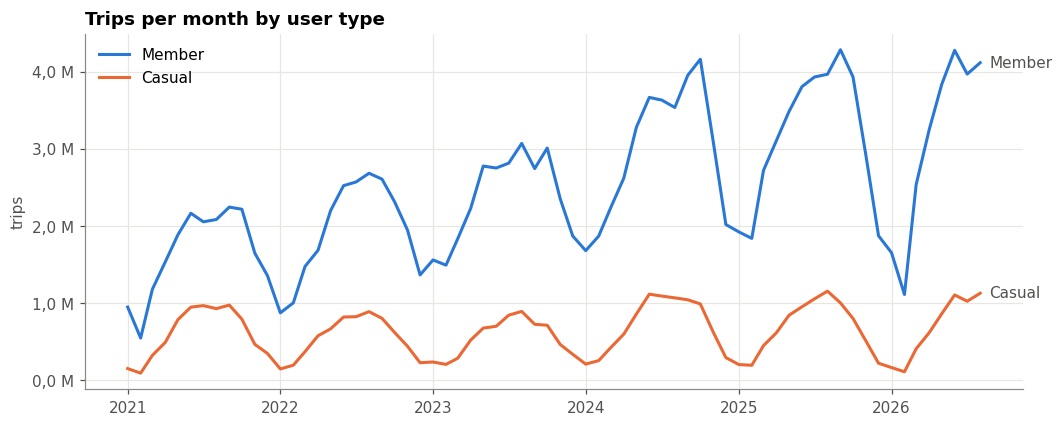

member_casual,member,casual,casual_share_%,peak_month_member,peak_month_casual
year,,,,,
2021,19.854.837,7.249.754,"26,7",2.244.422,973.194
2022,23.236.606,6.561.613,"22,0",2.683.238,888.145
2023,28.499.261,6.580.869,"18,8",3.070.103,891.037
2024,35.740.947,8.550.709,"19,3",4.161.861,1.114.711
2025,37.778.217,7.983.372,"17,4",4.285.181,1.154.007
2026,24.745.297,5.407.900,"17,9",4.278.139,1.126.639


In [9]:
by_user = monthly.pivot_table(index="month", columns="member_casual", values="trips", aggfunc="sum")

fig, ax = plt.subplots()
for user in ["member", "casual"]:
    ax.plot(by_user.index, by_user[user], color=COLORS[user], label=LABELS[user])
    ax.annotate(LABELS[user], (by_user.index[-1], by_user[user].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#52514e")
ax.yaxis.set_major_formatter(millions)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Trips per month by user type")
ax.set_ylabel("trips")
ax.legend(loc="upper left")
plt.show()

by_year = (monthly.assign(year=monthly.month.dt.year)
           .pivot_table(index="year", columns="member_casual", values="trips", aggfunc="sum")[["member", "casual"]])
by_year["casual_share_%"] = (by_year.casual / by_year.sum(axis=1) * 100).round(1)
by_year["peak_month_member"] = by_user.groupby(by_user.index.year).member.max()
by_year["peak_month_casual"] = by_user.groupby(by_user.index.year).casual.max()
by_year


**Reading the result.** Member trips peak at 2,2 M per month in 2021 and at 4,3 M in 2025; casual trips peak at
0,9 - 1,2 M in every year. Casual users are therefore a **shrinking minority**: 26,7 % of the trips in 2021,
17,4 % in 2025 (17,9 % in January - August 2026). A statement about "the" rider is mostly a statement about
members, and a model of daily demand is mostly a model of commuting.


### 3.2 The shift to e-bikes
For the "going green" theme the bike type matters. The chart shows the **share of trips on an e-bike** per
month and user type. A share is easier to compare over time than raw counts, because the counts are dominated
by the season.

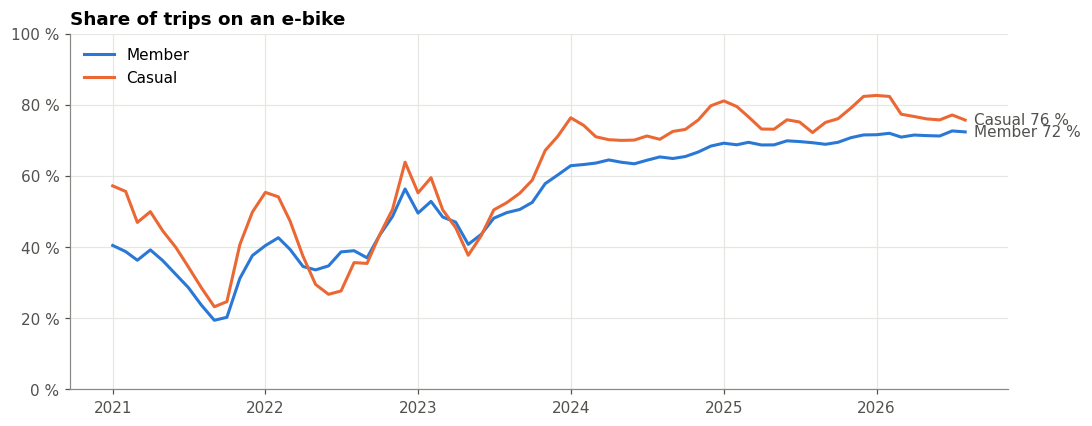

rideable_type,classic_bike,electric_bike,ebike_share_%
year,,,
2021,18.477.215,8.627.376,"31,8"
2022,18.076.534,11.721.685,"39,3"
2023,17.478.853,17.601.277,"50,2"
2024,14.997.625,29.294.031,"66,1"
2025,13.514.461,32.247.128,"70,5"
2026,8.267.501,21.885.696,"72,6"


In [10]:
share = (monthly.pivot_table(index=["month", "member_casual"], columns="rideable_type", values="trips", aggfunc="sum")
         .assign(ebike_share=lambda d: d.electric_bike / (d.electric_bike + d.classic_bike) * 100)
         .ebike_share.unstack())

fig, ax = plt.subplots()
for user in ["member", "casual"]:
    ax.plot(share.index, share[user], color=COLORS[user], label=LABELS[user])
    ax.annotate(f"{LABELS[user]} {share[user].iloc[-1]:.0f} %", (share.index[-1], share[user].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color="#52514e")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Share of trips on an e-bike")
ax.legend(loc="upper left")
plt.show()

yearly = monthly.assign(year=monthly.month.dt.year).pivot_table(index="year", columns="rideable_type",
                                                                values="trips", aggfunc="sum")
yearly["ebike_share_%"] = (yearly.electric_bike / yearly.sum(axis=1) * 100).round(1)
yearly

**Trend test.** Is the rise in e-bike share a real trend or noise? The chart suggests a rise; this test puts a
number on it.

**What the code does**
1. `total_share`: the e-bike share per month for **all users together** - 68 numbers between 0 and 1.
2. `np.arange(len(total_share))`: the month number 0, 1, 2, ... 67 - simply the order in time.
3. `stats.spearmanr(...)` compares two rankings of the same 68 months: sorted **by date** and sorted **by
   e-bike share**. If both orders are identical (every month higher than the one before), rho = 1; a random
   order gives rho ≈ 0; a perfect decline gives rho = -1.

**Mini example** with 5 months, where month 3 dips a little:

| Month (rank in time) | E-bike share | Rank by share | Difference d | d² |
| --- | --- | --- | --- | --- |
| 1 | 30 % | 1 | 0 | 0 |
| 2 | 35 % | 3 | -1 | 1 |
| 3 | 33 % | 2 | 1 | 1 |
| 4 | 40 % | 4 | 0 | 0 |
| 5 | 45 % | 5 | 0 | 0 |

rho = 1 - 6 · Σd² / (n · (n² - 1)) = 1 - 6 · 2 / (5 · 24) = **0,9**. One small dip barely lowers rho: the
test asks *"does it keep going up?"*, not *"does it go up by the same amount every month?"*.

**Why Spearman and not a straight line.** Pearson correlation or linear regression assume a straight line. This
curve swings widely in 2021 - 2023, climbs steeply in 2023 - 2024 and is nearly flat after that; Spearman only looks at the order, so it fits a trend that is
not linear. We report rho itself as the effect size, not only the p-value.

In [11]:
total_share = (monthly.pivot_table(index="month", columns="rideable_type", values="trips", aggfunc="sum")
               .pipe(lambda d: d.electric_bike / d.sum(axis=1)))
rho, p = stats.spearmanr(np.arange(len(total_share)), total_share.values)
print(f"Spearman rho = {fmt(rho, '.3f')}, p = {fmt(p, '.2e')}, n = {len(total_share)} months")
print(f"e-bike share first 12 months: {fmt(total_share.iloc[:12].mean() * 100, '.1f')} %, "
      f"last 12 months: {fmt(total_share.iloc[-12:].mean() * 100, '.1f')} %")

Spearman rho = 0,949, p = 9,06e-35, n = 68 months
e-bike share first 12 months: 34,0 %, last 12 months: 72,1 %


**Reading the result**
- **rho** is the effect size: how closely the order by share follows the order in time. Close to 1 means later
  months almost always have a higher e-bike share - a very strong rising trend.
- **p** is the chance of a rank correlation at least this strong if there were *no* trend at all. In
  scientific notation: 9,06e-35 means 0,000...906 with 34 zeros after the comma - practically zero.
- **n** is the number of months.
- The **first 12 vs last 12 months** line is not a test; it turns the trend into something you can picture -
  the share more than doubled.

**Two caveats**
1. **The p-value is too optimistic.** The test assumes the 68 months are independent measurements. In a time
   series they are not: a month looks a lot like the month before, and the season repeats every year. The
   real uncertainty is therefore larger than the p-value suggests. The conclusion holds - rho ≈ 0,95 over five
   years is far too strong to be chance - but the exact p-value should not be quoted as evidence.
2. **The test covers the whole period, not the last months.** rho is dominated by the steep rise of 2021 -
   2024. The chart shows the share flattening at ~70 - 73 % from 2025 on. Whether it is *still* rising cannot be
   read from this test; a hypothesis about 2026 needs a test on the recent period only (for example the last
   24 months).
3. **The share also depends on supply.** The swings of 2021 - 2023 do not follow the season: the member share
   falls from about 40 % in January 2021 to 20 % in September 2021, and dips again in the summer of 2022 and the
   spring of 2023, for members and casual users alike. The most likely reason is the number of e-bikes on the
   street (fleet changes), which the data does not record. The share therefore measures *use*, not *preference*;
   `03_hypothesis.ipynb` returns to this point.

### 3.3 When during the week do people ride?
For one full year (2025) we count trips per weekday and hour, separately for members and casual users.
Darker means more trips. Each panel has its own scale, because we compare the *pattern*, not the volume.

336 rows in 8,1 s


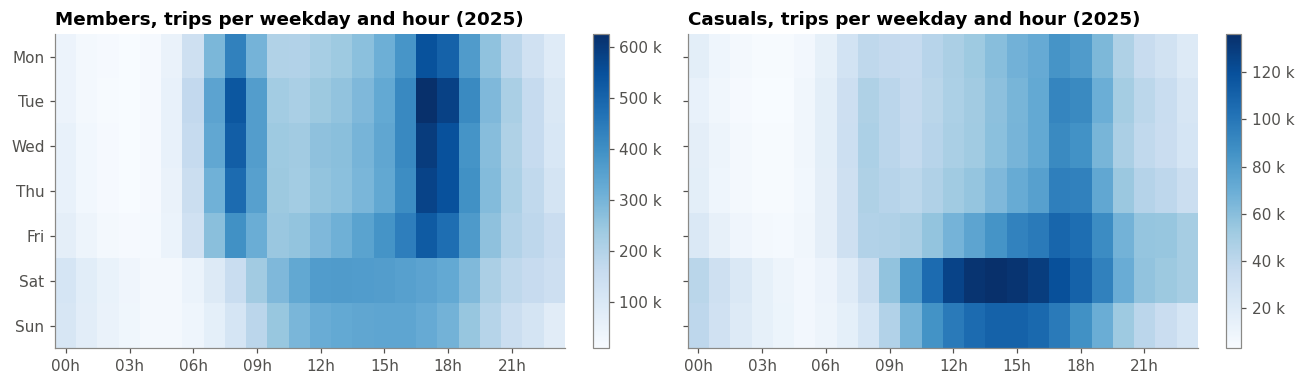

In [12]:
week = sql("""
    SELECT extract(isodow FROM started_at)::int AS weekday, extract(hour FROM started_at)::int AS hour,
           member_casual, count(*) AS trips
    FROM citibike.trips WHERE started_at >= '2025-01-01' AND started_at < '2026-01-01'
    GROUP BY 1, 2, 3
""")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, user in zip(axes, ["member", "casual"]):
    grid = week[week.member_casual == user].pivot(index="weekday", columns="hour", values="trips")
    im = ax.imshow(grid.values, aspect="auto", cmap="Blues")
    ax.set_title(f"{LABELS[user]}s, trips per weekday and hour (2025)")
    ax.set_yticks(range(7), days)
    ax.set_xticks(range(0, 24, 3), [f"{h:02d}h" for h in range(0, 24, 3)])
    ax.grid(False)
    fig.colorbar(im, ax=ax, format=thousands, fraction=0.04)
plt.tight_layout()
plt.show()

**Reading the result.** Members show a clear **commuter pattern**: peaks around 08h and 17h-18h on
weekdays. Casual users ride mostly in the **afternoon and at the weekend** - a leisure pattern. The two groups
use the system for different purposes, which matters for any model that predicts demand or user type.

### 3.4 Trips per day: gaps and unusual days
A monthly total hides single days: storms, snow, system outages or days missing from the data. One query
counts the trips per day, bike type and user type (~8.000 rows); the weather analysis in 3.5 reuses it.

To compare days across seasons and years we use **relative demand**: the trips of a day divided by the
median of the same month and the same kind of day (weekday or weekend). Season and growth drop out; 1,0 is
a normal day, 0,5 a day with half the usual trips.

8.268 rows in 37,1 s
2.067 days with trips, 2021-01-01 -> 2026-08-31
Days without any trip: ['2021-02-02', '2026-02-23']


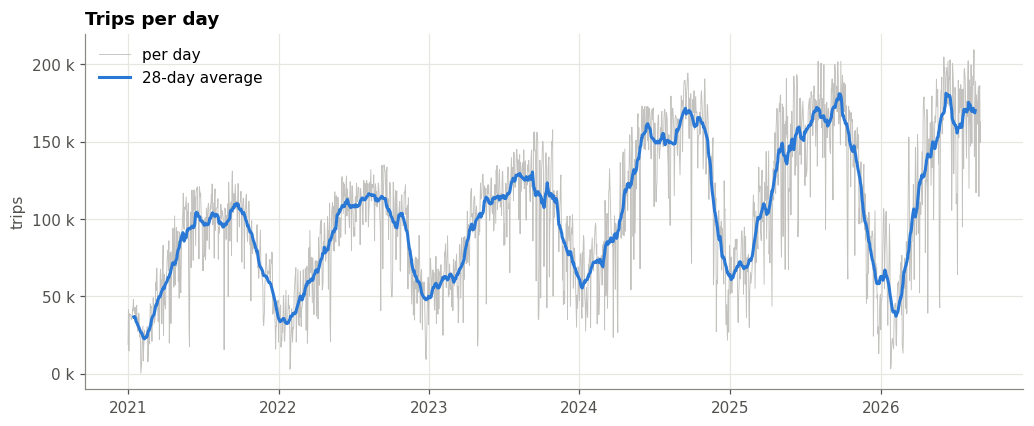

The 10 days with the lowest relative demand:


rideable_type,trips,relative
day,,
2021-02-01 00:00:00,238,"0,01"
2026-01-25 00:00:00,3.051,"0,07"
2026-01-26 00:00:00,6.045,"0,08"
2022-01-29 00:00:00,2.821,"0,13"
2021-08-22 00:00:00,15.442,"0,15"
2021-05-30 00:00:00,17.283,"0,19"
2024-11-28 00:00:00,27.108,"0,20"
2025-12-27 00:00:00,12.864,"0,20"
2022-12-25 00:00:00,9.118,"0,20"


In [13]:
daily_raw = sql("""
    SELECT started_at::date AS day, member_casual, rideable_type, count(*) AS trips
    FROM citibike.trips WHERE started_at >= '2021-01-01'
    GROUP BY 1, 2, 3
""")
daily_raw["day"] = pd.to_datetime(daily_raw.day)

days = daily_raw.pivot_table(index="day", columns="rideable_type", values="trips", aggfunc="sum", fill_value=0)
days["trips"] = days.classic_bike + days.electric_bike
days["ebike_share"] = days.electric_bike / days.trips * 100
members = daily_raw[daily_raw.member_casual == "member"].groupby("day").trips.sum()
days["member_share"] = members.reindex(days.index, fill_value=0) / days.trips * 100
days["weekend"] = days.index.dayofweek >= 5
days["relative"] = days.trips / days.groupby([days.index.to_period("M"), "weekend"]).trips.transform("median")

missing_days = pd.date_range(days.index.min(), days.index.max(), freq="D").difference(days.index)
print(f"{fmt(len(days))} days with trips, {days.index.min():%Y-%m-%d} -> {days.index.max():%Y-%m-%d}")
print("Days without any trip:", list(missing_days.strftime("%Y-%m-%d")) or "none")

fig, ax = plt.subplots()
ax.plot(days.index, days.trips, color="#c3c2be", linewidth=0.6, label="per day")
ax.plot(days.index, days.trips.rolling(28, center=True).mean(), color=COLORS["member"], label="28-day average")
ax.yaxis.set_major_formatter(thousands)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Trips per day")
ax.set_ylabel("trips")
ax.legend(loc="upper left")
plt.show()

print("The 10 days with the lowest relative demand:")
days.nsmallest(10, "relative")[["trips", "relative"]].round(2)

**What to look for.** Days without any trip are gaps in the data (or a full outage) and must be known before
a model is trained on daily counts. Days with a very low relative demand are either weather (checked in
3.5), holidays (checked in 3.6), or partial outages; a day that none of these explain is a candidate data problem.

### 3.5 Weather
The weather is the strongest day-to-day driver of bike use, and it can also change the choice between a
classic bike and an e-bike (heat, rain, wind). For trends and for the hypothesis it is a **confounder**: a
warm year against a cool one can look like a change in behaviour.

**Source.** The table `citibike.weather_daily` in the project database: daily observations of the NOAA weather
station **New York Central Park** (`USW00094728`), loaded by the ingest backend (`POST /api/weather/runs`) from
the public NCEI *daily summaries* service. The notebook only queries the table, so every run sees the same
numbers and NOAA does not have to be reachable. Variables: maximum and minimum temperature (°C), precipitation
and snowfall (mm), snow depth (mm) and average wind speed (m/s). NOAA has no daily mean for this station, so
`tavg_c` is the average of maximum and minimum.

**Limits.** One station for the whole city; precipitation is a day total, so rain at night counts the same as
rain at rush hour. Holidays are not corrected for here; 3.6 looks at them separately.

In [14]:
weather = sql("""
    SELECT day, tmax_c, tmin_c, prcp_mm, snow_mm, snow_depth_mm, wind_ms
    FROM citibike.weather_daily
    WHERE station = 'USW00094728' AND day BETWEEN :start AND :end
    ORDER BY day
""", start=days.index.min().date(), end=days.index.max().date())
weather["day"] = pd.to_datetime(weather.day)
weather = weather.set_index("day")
weather["tavg_c"] = (weather.tmax_c + weather.tmin_c) / 2

missing_weather = days.index.difference(weather.index)
print(f"{fmt(len(weather))} weather days; trip days without weather: {len(missing_weather)}")
print("Empty values per variable:", weather.isna().sum().to_dict())

days = days.drop(columns=weather.columns, errors="ignore").join(weather)
days["rain"] = pd.cut(days.prcp_mm, [-np.inf, 0, 2, 10, 25, np.inf],
                      labels=["dry", "0 - 2 mm", "2 - 10 mm", "10 - 25 mm", "> 25 mm"])   # right-closed: exactly 2,0 mm is "0 - 2 mm"
days["temperature"] = pd.cut(days.tmax_c, [-np.inf, 0, 10, 20, 25, 30, 35, np.inf],
                             labels=["< 0", "0 - 10", "10 - 20", "20 - 25", "25 - 30", "30 - 35", "> 35"])
weather.describe().T.round(1)

2.069 rows in 0,6 s
2.069 weather days; trip days without weather: 0
Empty values per variable: {'tmax_c': 0, 'tmin_c': 0, 'prcp_mm': 0, 'snow_mm': 0, 'snow_depth_mm': 4, 'wind_ms': 23, 'tavg_c': 0}


,count,mean,std,min,25%,50%,75%,max
tmax_c,2.069,"17,8","9,9","-9,3","10,0","18,9","26,1","37,8"
tmin_c,2.069,"10,0","9,0","-16,1","2,8","10,0","17,8","27,8"
prcp_mm,2.069,"3,5","10,2","0,0","0,0","0,0","1,5","181,1"
snow_mm,2.069,"1,4","15,1","0,0","0,0","0,0","0,0","376,0"
snow_depth_mm,2.065,"5,7","30,8","0,0","0,0","0,0","0,0","360,0"
wind_ms,2.046,"2,2","1,1","0,3","1,4","2,1","2,9","6,6"
tavg_c,2.069,"13,9","9,3","-12,0","6,4","14,4","22,2","32,8"


**Weather and the number of trips.** Left: the median relative demand per precipitation class - because
relative demand compares a day with its own month, season and growth are already taken out. Right: trips per
day against the maximum temperature for **dry days**, one colour per year (the colours are labels, not an order); here season and temperature are
the same thing, so the chart shows the shape of the relation, not a clean effect.

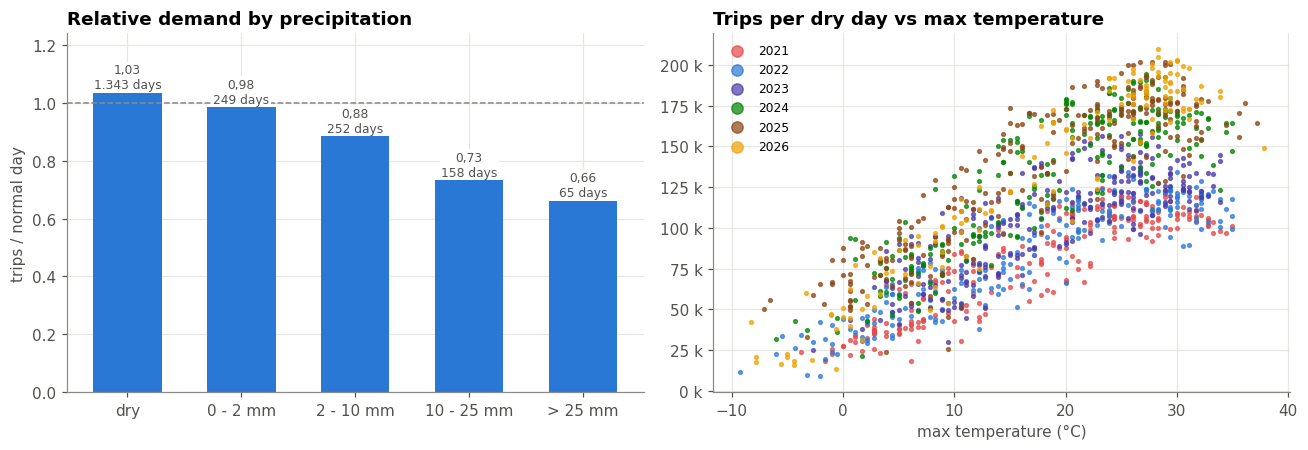

Spearman rho (precipitation vs relative demand) = -0,448, p = 1,02e-102, n = 2.067 days


,days,median_relative
rain,,
dry,1.343,"1,03"
0 - 2 mm,249,"0,98"
2 - 10 mm,252,"0,88"
10 - 25 mm,158,"0,73"
> 25 mm,65,"0,66"


In [15]:
rain_effect = days.groupby("rain", observed=True).agg(days=("trips", "size"),
                                                     median_relative=("relative", "median"))
rho_rain, p_rain = stats.spearmanr(days.prcp_mm, days.relative, nan_policy="omit")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.bar(rain_effect.index.astype(str), rain_effect.median_relative, color=COLORS["member"], width=0.6)
for x, (n, v) in enumerate(zip(rain_effect.days, rain_effect.median_relative)):
    ax1.annotate(f"{fmt(v, '.2f')}\n{fmt(n)} days", (x, v), xytext=(0, 3), textcoords="offset points",
                 ha="center", color="#52514e", fontsize=8,
                 bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})   # keeps the 1,0 line out of the label
ax1.axhline(1, color="#8a8986", linewidth=1, linestyle="--")
ax1.set_ylim(0, rain_effect.median_relative.max() * 1.2)   # room for the two-line labels above the bars
ax1.set_title("Relative demand by precipitation")
ax1.set_ylabel("trips / normal day")

# One distinct colour per year: the years are categories here, a darker colour does not mean "more".
YEAR_COLORS = {2021: "#e34948", 2022: "#2a78d6", 2023: "#4a3aa7", 2024: "#008300", 2025: "#8b4513", 2026: "#eda100"}
dry = days[days.rain == "dry"]
for year in sorted(dry.index.year.unique()):
    d = dry[dry.index.year == year]
    ax2.scatter(d.tmax_c, d.trips, s=6, alpha=0.7, color=YEAR_COLORS[year], label=str(year))
ax2.yaxis.set_major_formatter(thousands)
ax2.set_title("Trips per dry day vs max temperature")
ax2.set_xlabel("max temperature (°C)")
ax2.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

print(f"Spearman rho (precipitation vs relative demand) = {fmt(rho_rain, '.3f')}, p = {fmt(p_rain, '.2e')}, "
      f"n = {fmt(days.prcp_mm.notna().sum())} days")
rain_effect.round(2)

**Weather and the choice of bike.** Does rain change the share of trips made on an e-bike? The chart shows, per
year, the **median e-bike share** on dry days, on days with 2 - 10 mm and on days with more than 10 mm of
precipitation; the number next to each row is the difference between the wettest and the dry days. Comparing
within one year keeps the yearly rise of the share (3.2) out of the comparison. Days with a trace of rain
(0 - 2 mm) are left out: it may have rained at night or for a few minutes.

The printout below the chart repeats the check with the season taken out as well: each day's share minus the
median share of the **29 days around it** (`ebike_share_dev`, in percentage points), and the Spearman correlation
of that deviation with temperature, precipitation and wind.

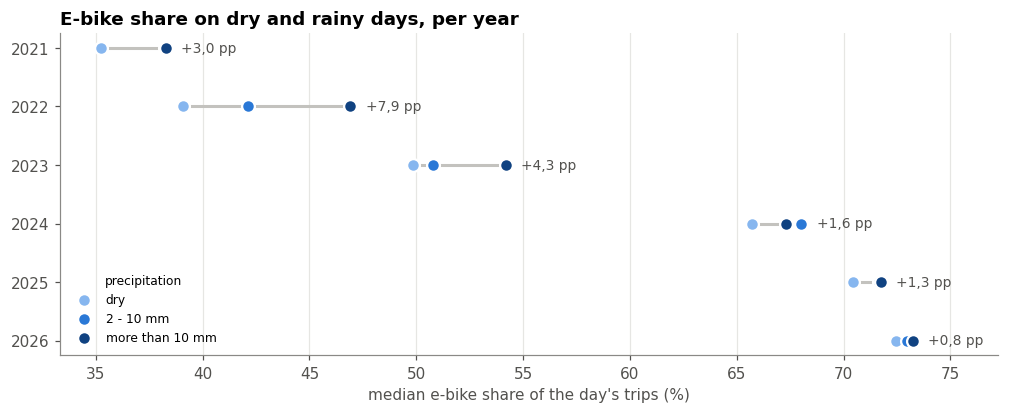

Median e-bike share per year and precipitation group (%), and days per group:


rain_group,dry,2 - 10 mm,more than 10 mm,difference_pp
year,,,,
2021,"35,2","38,2","38,3","3,0"
2022,"39,1","42,1","46,9","7,9"
2023,"49,9","50,8","54,2","4,3"
2024,"65,7","68,0","67,3","1,6"
2025,"70,4","71,7","71,8","1,3"
2026,"72,5","73,0","73,2","0,8"


rain_group,dry,2 - 10 mm,more than 10 mm
year,,,
2021,225,44,43
2022,243,42,44
2023,242,38,49
2024,241,47,32
2025,244,43,36
2026,148,38,19


With the season taken out too: median deviation from the 29 days around it (pp), per precipitation class:


,days,ebike_share_dev_pp
rain,,
dry,1.343,"-0,26"
0 - 2 mm,249,"0,00"
2 - 10 mm,252,"0,92"
10 - 25 mm,158,"2,04"
> 25 mm,65,"2,06"


Spearman rho (tmax_c vs e-bike share deviation) = -0,095, p = 1,67e-05
Spearman rho (prcp_mm vs e-bike share deviation) = 0,342, p = 1,02e-57
Spearman rho (wind_ms vs e-bike share deviation) = 0,099, p = 6,71e-06
The 10 days with the lowest relative demand, with their weather:


,trips,relative,tmax_c,prcp_mm,snow_mm,snow_depth_mm,wind_ms
day,,,,,,,
2021-02-01 00:00:00,238,"0,01","1,1","47,0",376,130,"6,4"
2026-01-25 00:00:00,3.051,"0,07","-5,6","45,7",290,25,"4,4"
2026-01-26 00:00:00,6.045,"0,08","-2,8","0,5",0,229,"2,8"
2022-01-29 00:00:00,2.821,"0,13","-1,6","19,6",185,150,"5,6"
2021-08-22 00:00:00,15.442,"0,15","24,4","67,8",0,0,"2,3"
2021-05-30 00:00:00,17.283,"0,19","10,6","22,6",0,0,"3,4"
2024-11-28 00:00:00,27.108,"0,20","9,4","21,8",0,0,"2,5"
2025-12-27 00:00:00,12.864,"0,20","-0,6","5,6",66,102,"2,9"
2022-12-25 00:00:00,9.118,"0,20","-2,1","0,0",0,0,"3,8"


In [16]:
days["ebike_share_dev"] = days.ebike_share - days.ebike_share.rolling(29, center=True, min_periods=15).median()
days["rain_group"] = pd.cut(days.prcp_mm, [-np.inf, 0, 2, 10, np.inf],
                            labels=["dry", "trace", "2 - 10 mm", "more than 10 mm"])

RAIN_COLORS = {"dry": "#86b6ef", "2 - 10 mm": "#2a78d6", "more than 10 mm": "#104281"}   # light -> dark = more rain
per_year = (days.groupby([days.index.year, "rain_group"], observed=True).ebike_share.median()
            .unstack()[list(RAIN_COLORS)].rename_axis("year"))
per_year["difference_pp"] = per_year["more than 10 mm"] - per_year["dry"]

fig, ax = plt.subplots(figsize=(11, 3.8))
rows = range(len(per_year))
ax.hlines(rows, per_year[list(RAIN_COLORS)].min(axis=1), per_year[list(RAIN_COLORS)].max(axis=1),
          color="#c3c2be", linewidth=2, zorder=1)
for group, color in RAIN_COLORS.items():
    ax.scatter(per_year[group], rows, s=70, color=color, edgecolor="white", linewidth=1.5, zorder=2, label=group)
for row, (year, values) in zip(rows, per_year.iterrows()):
    ax.annotate(f"{fmt(values.difference_pp, '+.1f')} pp", (values[list(RAIN_COLORS)].max(), row),
                xytext=(10, 0), textcoords="offset points", va="center", color="#52514e", fontsize=9)
ax.set_yticks(list(rows), per_year.index.astype(str))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("median e-bike share of the day's trips (%)")
ax.set_title("E-bike share on dry and rainy days, per year")
ax.set_xlim(right=per_year[list(RAIN_COLORS)].max().max() + 4)   # room for the difference labels
ax.legend(title="precipitation", fontsize=8, title_fontsize=8, loc="lower left")
plt.show()

print("Median e-bike share per year and precipitation group (%), and days per group:")
display(per_year.round(1))
display(days.groupby([days.index.year, "rain_group"], observed=True).size().unstack()[list(RAIN_COLORS)].rename_axis("year"))

print("With the season taken out too: median deviation from the 29 days around it (pp), per precipitation class:")
display(days.groupby("rain", observed=True).agg(days=("trips", "size"),
                                                ebike_share_dev_pp=("ebike_share_dev", "median")).round(2))
for var in ["tmax_c", "prcp_mm", "wind_ms"]:
    rho, p = stats.spearmanr(days[var], days.ebike_share_dev, nan_policy="omit")
    print(f"Spearman rho ({var} vs e-bike share deviation) = {fmt(rho, '.3f')}, p = {fmt(p, '.2e')}")

print("The 10 days with the lowest relative demand, with their weather:")
days.nsmallest(10, "relative")[["trips", "relative", "tmax_c", "prcp_mm", "snow_mm", "snow_depth_mm", "wind_ms"]].round(2)

**Reading the result**

- **Rain lowers demand, step by step.** Median relative demand: dry 1,03 -> 0 - 2 mm 0,98 -> 2 - 10 mm 0,88 ->
  10 - 25 mm 0,73 -> more than 25 mm 0,66. Spearman rho = -0,448 over 2.067 days. `03_hypothesis.ipynb` §5 tests
  this formally (H-D) and leaves the holidays of 3.6 out.
- **Temperature** (right chart, dry days): trips rise with the maximum temperature and level off around 25 - 30 °C;
  every year's cloud lies higher than the one before (growth, 3.2), so this chart shows the shape, not an effect size.
- **Rain raises the e-bike share, every year.** On days with more than 10 mm the median share is higher than on
  dry days in all six years: +3,0 pp (2021), +7,9 (2022), +4,3 (2023), +1,6 (2024), +1,3 (2025) and +0,8 pp (2026,
  January - August, 19 wet days). The check with the season taken out agrees: +0,92 pp at 2 - 10 mm, +2,04 pp at
  10 - 25 mm and +2,06 pp above 25 mm against the 29 days around, -0,26 pp on dry days (rho = 0,342).
- **The rain effect on the bike choice is shrinking.** From +4 - 8 pp in 2022 - 2023 to +1 - 2 pp since 2024. A
  likely reading: with 70 % of the trips already on an e-bike, fewer classic riders are left to switch on a wet day;
  the data shows the shrinking, not the reason. Temperature (rho = -0,095) and wind (rho = 0,099) hardly matter.
- **The lowest days of 3.4 are weather or holidays.** Six are snow days (2021-02-01, 2022-01-29, 2025-12-27,
  2026-01-25/26/27 - on 26 and 27 January 2026 it hardly snowed, but 229 and 203 mm of snow lay on the ground),
  two heavy rain (2021-08-22 with 67,8 mm, 2021-05-30 with 22,6 mm at 10,6 °C), Thanksgiving 2024 with 21,8 mm of
  rain, and Christmas Day 2022: dry, so a holiday effect (3.6).

### 3.6 Holidays
A holiday changes *why* people ride: commuters stay home, leisure riders go out. For the daily counts that is a
second calendar effect next to the weekend, and it can explain low days that the weather does not (3.4).

**Source.** The view `citibike.calendar_day` in the project database: one row per date, built on the table
`citibike.holiday`, which the ingest backend (`POST /api/calendar/runs`) fills from the open-source `holidays`
package (version 0.105, United States + New York State). The notebook only queries the view.
- `public_holidays`: holidays with a day off (federal and New York State). A holiday on a weekend has two dates:
  the actual date (`has_public_holiday`) and the weekday off (`is_observed_day_off`, e.g. Monday 26 December
  2022 for Christmas on a Sunday).
- `other_holidays`: observances without a day off (Good Friday, Easter Sunday, Christmas Eve, New Year's Eve,
  Halloween, ...).

**Questions.** (1) Which holidays change demand, and by how much? (2) Do commuters stay home on a day off - is
the member share lower and do the 08h / 17h peaks of 3.3 disappear? (3) Easter moves every year: is it visible?

**Day types.** A *weekday day off* is a Monday - Friday with a public holiday or an observed day off; Saturday and
Sunday are kept apart; every other day is a *workday*. Relative demand is the same as in 3.4: a weekday is
compared with the weekdays of its month, a weekend day with the weekend days.

In [17]:
calendar = sql("""
    SELECT day, iso_dow, has_public_holiday, is_observed_day_off, public_holidays, other_holidays
    FROM citibike.calendar_day
    WHERE day BETWEEN :start AND :end
""", start=days.index.min().date(), end=days.index.max().date())
calendar["day"] = pd.to_datetime(calendar.day)
calendar = calendar.set_index("day")

days = days.drop(columns=calendar.columns, errors="ignore").join(calendar)
days["day_off"] = (days.has_public_holiday | days.is_observed_day_off) & ~days.weekend
days["day_type"] = np.select([days.iso_dow == 7, days.iso_dow == 6, days.day_off],
                             ["Sunday", "Saturday", "weekday day off"], "workday")
print(f"{fmt(len(days))} days, of which {fmt(int(days.day_off.sum()))} weekday days off")

print("Per day type: median relative demand and median member share")
display(days.groupby("day_type").agg(days=("trips", "size"), median_trips=("trips", "median"),
                                     median_relative=("relative", "median"),
                                     median_member_share_pct=("member_share", "median"))
        .loc[["workday", "weekday day off", "Saturday", "Sunday"]].round(3))

# One row per (day, holiday name): a day can carry two names (Washington's Birthday and Susan B. Anthony Day).
names = pd.concat([
    days.public_holidays.dropna().str.split("; ").explode().to_frame("name").assign(category="public"),
    days.other_holidays.dropna().str.split("; ").explode().to_frame("name").assign(category="unofficial"),
]).join(days[["weekend", "relative", "member_share"]])
by_holiday = (names.groupby(["category", "name"])
              .agg(days=("relative", "size"), on_weekdays=("weekend", lambda s: int((~s).sum())),
                   median_relative=("relative", "median"), median_member_share_pct=("member_share", "median"))
              .sort_values("median_relative"))
print("Per holiday name, lowest relative demand first:")
by_holiday.round(3)

2.069 rows in 0,5 s
2.067 days, of which 75 weekday days off
Per day type: median relative demand and median member share


,days,median_trips,median_relative,median_member_share_pct
day_type,,,,
workday,1.400,105.765,"1,000","83,512"
weekday day off,75,75.473,"0,829","79,663"
Saturday,296,101.928,"1,064","73,609"
Sunday,296,91.838,"0,963","74,143"


Per holiday name, lowest relative demand first:


days  on_weekdays  \
category   name                                                                 
public     Christmas Day                                       5            3   
           Christmas Day (observed)                            2            2   
           Thanksgiving Day                                    5            5   
unofficial Christmas Eve                                       5            3   
public     New Year's Day                                      6            4   
           Martin Luther King Jr. Day                          6            6   
unofficial New Year's Eve                                      5            3   
public     Independence Day                                    6            4   
           Independence Day (observed)                         2            2   
           Columbus Day                                        5            5   
           Labor Day                                           5            5   
unofficial Mother's Day                                        6            0   
public     New Year's Day (observed)                           2            2   
unofficial Groundhog Day                                       5            4   
public     Memorial Day                                        6            6   
unofficial Easter Sunday                                       6            0   
           Good Friday                                         6            6   
           Halloween                                           5            4   
           Saint Patrick's Day                                 6            5   
           Father's Day                                        6            0   
public     Juneteenth National Independence Day                6            4   
           Washington's Birthday                               6            6   
unofficial Valentine's Day                                     6            4   
public     Susan B. Anthony Day                                6            4   
           Veterans Day                                        5            4   
           Veterans Day (observed)                             1            1   
           Juneteenth National Independence Day (observed)     2            2   
           Lincoln's Birthday                                  6            4   
           Election Day                                        5            5   
unofficial Election Day                                        1            1   
public     Lincoln's Birthday (observed)                       2            2   

                                                            median_relative  \
category   name                                                               
public     Christmas Day                                              0.317   
           Christmas Day (observed)                                   0.398   
           Thanksgiving Day                                           0.430   
unofficial Christmas Eve                                              0.469   
public     New Year's Day                                             0.692   
           Martin Luther King Jr. Day                                 0.722   
unofficial New Year's Eve                                             0.730   
public     Independence Day                                           0.745   
           Independence Day (observed)                                0.788   
           Columbus Day                                               0.793   
           Labor Day                                                  0.805   
unofficial Mother's Day                                               0.806   
public     New Year's Day (observed)                                  0.814   
unofficial Groundhog Day                                              0.900   
public     Memorial Day                                               0.914   
unofficial Easter Sunday                   

**Reading the result**

- **A weekday day off is a day between a workday and a weekend day.** Median 75.473 trips against 105.765 on a
  workday; relative demand **0,829, about 17 % fewer trips** than a normal weekday of the same month. The member
  share drops from **83,5 %** (workday) to **79,7 %**, still above the weekend level (73,6 - 74,1 %).
- **Holidays differ a lot, so one holiday flag is too coarse.** The largest drops: Christmas Day 0,32 (its observed
  weekday 0,40), Thanksgiving 0,43, Christmas Eve 0,47 - an *unofficial* day, but a stronger effect than most public
  holidays - New Year's Day 0,69, Martin Luther King Jr. Day 0,72, New Year's Eve 0,73, Independence Day 0,75,
  Columbus Day 0,79 and Labor Day 0,81.
- **Some public holidays hardly change demand:** Memorial Day 0,91, Juneteenth 0,98, Washington's Birthday 0,99,
  Veterans Day 1,00. The New York State holidays Lincoln's Birthday (1,10) and Election Day (1,20) even lie above
  a normal weekday: for most riders they are no day off.
- **Leisure days show in the member share:** Independence Day 66,3 %, Labor Day 69,1 %, Memorial Day 71,0 % and
  Thanksgiving 73,2 % lie at or below the weekend level; Martin Luther King Jr. Day (88,2 %) and Washington's Birthday
  (86,7 %) keep a workday mix with fewer trips.
- **Easter is barely visible at day level:** Good Friday 0,95 (6 weekdays) and Easter Sunday 0,92 (compared with
  other weekend days). A spring-break effect would need the school calendar, which is not in the data.
- Each name occurs at most 6 times in 2021 - 2026, so a model cannot learn a separate effect per holiday; 04 has
  to group them (for example by the size of the drop above).

**Do commuters stay home?** The hourly pattern per day type, all years: for each user group and day type the
share of its trips that start in each hour (the hours of a line add up to 100 %). If commuting stops on a day off,
the weekday day off should lose the 08h and 17h peaks of a workday and look like a weekend day.

192 rows in 40,5 s


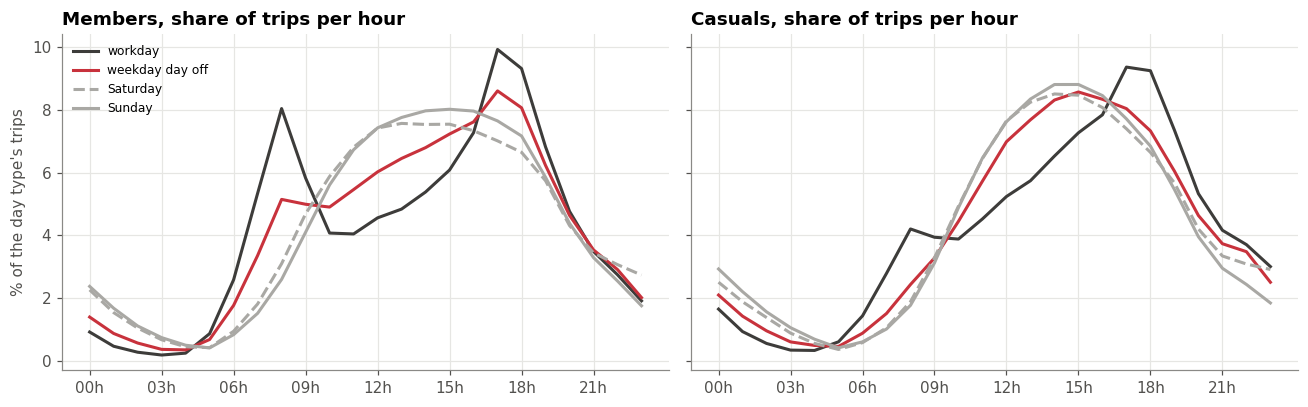

Share of trips in the commuter hours (07h - 09h and 16h - 18h), %:


day_type,workday,weekday day off,Saturday,Sunday
member_casual,,,,
casual,"37,4","30,9","28,4","28,9"
member,"45,7","37,8","30,6","31,0"


In [18]:
profile = sql("""
    SELECT extract(hour FROM t.started_at)::int AS hour,
           CASE WHEN c.iso_dow = 7 THEN 'Sunday'
                WHEN c.iso_dow = 6 THEN 'Saturday'
                WHEN c.has_public_holiday OR c.is_observed_day_off THEN 'weekday day off'
                ELSE 'workday' END AS day_type,
           t.member_casual, count(*) AS trips
    FROM citibike.trips t
    JOIN citibike.calendar_day c ON c.day = t.started_at::date
    WHERE t.started_at >= '2021-01-01'
    GROUP BY 1, 2, 3
""")
profile["share_pct"] = profile.trips / profile.groupby(["day_type", "member_casual"]).trips.transform("sum") * 100

DAY_TYPE_STYLE = {"workday": ("#3d3c3a", "-"), "weekday day off": ("#c8323c", "-"),
                  "Saturday": ("#a9a8a4", "--"), "Sunday": ("#a9a8a4", "-")}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, user in zip(axes, ["member", "casual"]):
    for day_type, (color, style) in DAY_TYPE_STYLE.items():
        line = profile[(profile.member_casual == user) & (profile.day_type == day_type)].sort_values("hour")
        ax.plot(line.hour, line.share_pct, color=color, linestyle=style, label=day_type)
    ax.set_title(f"{LABELS[user]}s, share of trips per hour")
    ax.set_xticks(range(0, 24, 3), [f"{h:02d}h" for h in range(0, 24, 3)])
axes[0].set_ylabel("% of the day type's trips")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Share of trips in the commuter hours (07h - 09h and 16h - 18h), %:")
peak = profile[profile.hour.isin([7, 8, 9, 16, 17, 18])].groupby(["member_casual", "day_type"]).share_pct.sum()
peak.unstack("day_type")[["workday", "weekday day off", "Saturday", "Sunday"]].round(1)

**Reading the result**

- **Members on a workday** ride in two peaks, around 08h and 17h - 18h (45,7 % of their trips start in the commuter
  hours 07h - 09h and 16h - 18h). **On a weekday day off** the morning peak shrinks by about a third (some 5 % of the day's trips start at
  08h, against 8 % on a workday) and the evening peak is lower; the commuter hours hold **37,8 %**, against 30,6 % on Saturday and 31,0 % on Sunday.
- **Casual users** on a day off ride almost like at the weekend: 30,9 % in the commuter hours against 28,4 - 28,9 %
  at the weekend and 37,4 % on a workday.
- **So commuting drops on a day off but does not stop.** That fits the mixed picture above: on some holidays most
  offices stay open. Together with 3.3 this supports separate day types (workday, day off, Saturday, Sunday) as model
  features, rather than only a weekend flag.

## 4. Trip duration and distance

### 4.1 A fixed sample of 2025
Distributions and statistical tests do not need all 212 M trips. We take a **~0.4 % sample of 2025**
(~180 k trips): one complete year so every season is represented, the most recent full year, and small enough
to handle in pandas.

The sample keeps the trips whose `ride_id` ends in `00`. A `ride_id` is a random hexadecimal string, so this
is as unbiased as a random draw (1 in 16 x 16 = 256 trips), **but the same trips come back on every run**:
the numbers in this notebook and in its findings stay reproducible. `random()` would give a different sample
each time.

We also compute the **straight-line distance** between start and end (haversine formula on the coordinates)
and the average **speed**. A real route is longer than a straight line, so both are lower bounds.

In [19]:
sample = sql("""
    SELECT started_at, duration_s, member_casual, rideable_type,
           start_station_id, end_station_id, start_lat, start_lng, end_lat, end_lng
    FROM citibike.trips
    WHERE started_at >= '2025-01-01' AND started_at < '2026-01-01' AND right(ride_id, 2) = '00'
""")

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

sample["minutes"] = sample.duration_s / 60
sample["distance_km"] = haversine_km(sample.start_lat, sample.start_lng, sample.end_lat, sample.end_lng)
sample["speed_kmh"] = sample.distance_km / (sample.duration_s / 3600)
sample["round_trip"] = sample.start_station_id.notna() & (sample.start_station_id == sample.end_station_id)
sample.groupby("member_casual")[["minutes", "distance_km", "speed_kmh"]].describe(percentiles=[.5, .9]).round(2).T

178.652 rows in 21,7 s


member_casual        casual     member
minutes     count  31171.00  147481.00
            mean      19.47      11.12
            std       36.12      14.45
            min        1.02       1.00
            50%       12.68       8.20
            90%       36.15      22.10
            max     1411.05    1321.90
distance_km count  30989.00  147116.00
            mean       2.20       1.96
            std        1.78       1.69
            min        0.00       0.00
            50%        1.72       1.45
            90%        4.48       4.12
            max       20.49      18.85
speed_kmh   count  30989.00  147116.00
            mean       9.35      11.37
            std        4.66       3.97
            min        0.00       0.00
            50%        9.57      11.42
            90%       15.23      16.36
            max       25.20      26.86

**Is the sample representative?** The `ride_id` rule should behave like a random draw. We check it against
numbers we know exactly for all of 2025 (from 3.1): the sample size, the member share, the e-bike share and how
the trips spread over the months. For each share the 95 % margin of a random sample of this size is
1,96 · √(p · (1 - p) / n); a difference inside that margin is what chance alone produces.

In [20]:
pop = monthly[monthly.month.dt.year == 2025]
pop_total = pop.trips.sum()
n = len(sample)
print(f"sample: {fmt(n)} trips = {fmt(n / pop_total * 100, '.3f')} % of 2025 (expected 1/256 = {fmt(100 / 256, '.3f')} %)")

population = {
    "member share": pop.loc[pop.member_casual == "member", "trips"].sum() / pop_total,
    "e-bike share": pop.loc[pop.rideable_type == "electric_bike", "trips"].sum() / pop_total,
}
in_sample = {
    "member share": (sample.member_casual == "member").mean(),
    "e-bike share": (sample.rideable_type == "electric_bike").mean(),
}
pop_months = pop.groupby(pop.month.dt.month).trips.sum() / pop_total
sample_months = sample.started_at.dt.month.value_counts(normalize=True)
for m in range(1, 13):
    population[f"trips in month {m:02d}"] = pop_months.get(m, 0)
    in_sample[f"trips in month {m:02d}"] = sample_months.get(m, 0)

check = pd.DataFrame({"population_%": pd.Series(population) * 100, "sample_%": pd.Series(in_sample) * 100})
check["difference_pp"] = check["sample_%"] - check["population_%"]
check["margin_95_pp"] = 1.96 * np.sqrt(check["population_%"] / 100 * (1 - check["population_%"] / 100) / n) * 100
check["within_margin"] = check.difference_pp.abs() <= check.margin_95_pp
print(f"{check.within_margin.sum()} of {len(check)} shares within the 95 % margin "
      f"(by chance about 1 in 20 falls outside)")
check.round(3)

sample: 178.652 trips = 0,390 % of 2025 (expected 1/256 = 0,391 %)
13 of 14 shares within the 95 % margin (by chance about 1 in 20 falls outside)


,population_%,sample_%,difference_pp,margin_95_pp,within_margin
member share,"82,554","82,552","-0,002","0,176",True
e-bike share,"70,468","70,382","-0,086","0,212",True
trips in month 01,"4,642","4,583","-0,059","0,098",True
trips in month 02,"4,438","4,412","-0,026","0,096",True
trips in month 03,"6,922","7,069","0,148","0,118",False
trips in month 04,"8,139","8,220","0,081","0,127",True
trips in month 05,"9,451","9,449","-0,002","0,136",True
trips in month 06,"10,398","10,337","-0,061","0,142",True
trips in month 07,"10,896","10,915","0,019","0,144",True
trips in month 08,"11,191","11,240","0,049","0,146",True


**Reading the result.** The sample holds 178.652 trips, 0,390 % of 2025 against 0,391 % expected. 13 of the 14
shares lie within the 95 % margin: member share 82,55 % against 82,55 % in the population, e-bike share 70,38 %
against 70,47 %, and eleven of the twelve months within 0,14 pp of their weight. The one exception is March
(7,07 % of the sample against 6,92 % of the year: +0,15 pp with a margin of 0,12 pp). With 14 checks one miss is
what chance produces - about 1 in 20 is expected to fall outside - and a 0,15 pp surplus of March trips cannot
move a median or an effect size. The sample behaves like a random draw and can stand in for 2025.


### 4.2 Duration distribution
Trip durations are strongly **right-skewed**: most trips take a few minutes, a few take hours. On a normal
axis the tail would squash everything into one bar, so the x-axis is **logarithmic**. The dashed lines are
the medians.

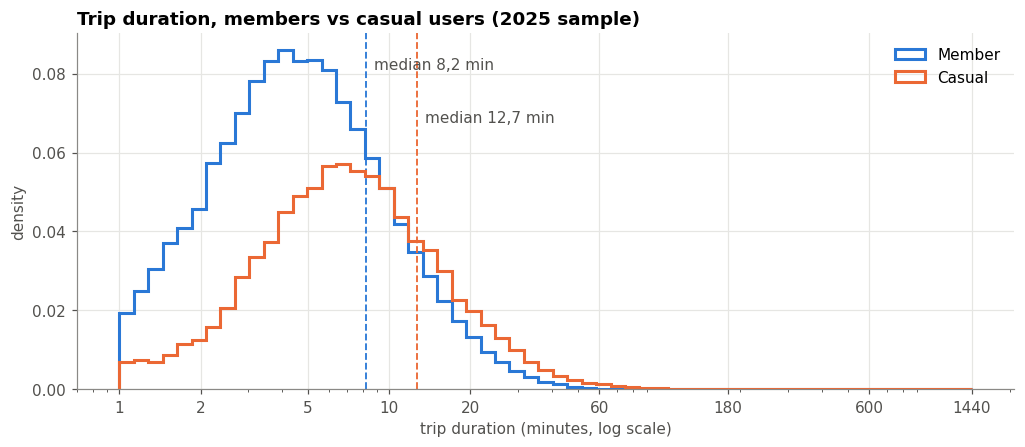

In [21]:
bins = np.logspace(0, np.log10(24 * 60), 60)
fig, ax = plt.subplots()
for user in ["member", "casual"]:
    m = sample.loc[sample.member_casual == user, "minutes"]
    ax.hist(m, bins=bins, histtype="step", linewidth=2, color=COLORS[user], density=True, label=LABELS[user])
    ax.axvline(m.median(), color=COLORS[user], linestyle="--", linewidth=1.2)
    ax.annotate(f"median {fmt(m.median(), '.1f')} min", (m.median(), ax.get_ylim()[1] * (0.9 if user == "member" else 0.75)),
                xytext=(5, 0), textcoords="offset points", color="#52514e")
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 20, 60, 180, 600, 1440], ["1", "2", "5", "10", "20", "60", "180", "600", "1440"])
ax.set_xlabel("trip duration (minutes, log scale)")
ax.set_ylabel("density")
ax.set_title("Trip duration, members vs casual users (2025 sample)")
ax.legend()
plt.show()

### 4.3 Is the difference in duration real? (Mann-Whitney U)
**Question:** do casual users ride longer than members?

**Test choice:** durations are far from normally distributed (see the skew above), so a t-test, which
assumes normality, is not appropriate. The **Mann-Whitney U test** compares the *ranks* of the two groups and
makes no assumption about the shape of the distribution.

**Effect size:** with hundreds of thousands of trips almost any difference is "significant", so the p-value
alone says little. We add the **rank-biserial correlation** (from -1 to 1; 0 = no difference) and the
difference in medians, which say *how big* the difference is.

In [22]:
casual = sample.loc[sample.member_casual == "casual", "duration_s"]
member = sample.loc[sample.member_casual == "member", "duration_s"]
u, p = stats.mannwhitneyu(casual, member, alternative="greater")
rank_biserial = 2 * u / (len(casual) * len(member)) - 1
print(f"n casual = {fmt(len(casual))}, n member = {fmt(len(member))}")
print(f"median casual = {fmt(casual.median() / 60, '.1f')} min, median member = {fmt(member.median() / 60, '.1f')} min")
print(f"Mann-Whitney U = {fmt(u, ',.0f')}, one-sided p = {fmt(p, '.2e')}")
print(f"rank-biserial correlation = {fmt(rank_biserial, '.3f')}  (|r| ~0,1 small, ~0,3 medium, ~0,5 large)")

n casual = 31.171, n member = 147.481
median casual = 12,7 min, median member = 8,2 min
Mann-Whitney U = 3.012.341.467, one-sided p = 0,00e+00
rank-biserial correlation = 0,311  (|r| ~0,1 small, ~0,3 medium, ~0,5 large)


### 4.4 Bike type and user type (chi-square test of independence)
**Question:** do members and casual users choose e-bikes equally often?

The chi-square test checks whether two categorical variables are independent. We run it on the **full 2025
counts** (no sample needed - these are aggregates). **Cramér's V** (0 = independent, 1 = fully dependent)
is the effect size.

In [23]:
table = (monthly[monthly.month.dt.year == 2025]
         .pivot_table(index="member_casual", columns="rideable_type", values="trips", aggfunc="sum"))
chi2, p, dof, _ = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
display(table.assign(ebike_share_pct=lambda d: (d.electric_bike / d.sum(axis=1) * 100).round(1)))
print(f"chi2 = {fmt(chi2, ',.0f')}, dof = {dof}, p = {fmt(p, '.2e')}, Cramer's V = {fmt(cramers_v, '.3f')}")

rideable_type,classic_bike,electric_bike,ebike_share_pct
member_casual,,,
casual,1.973.346,6.010.026,"75,3"
member,11.541.115,26.237.102,"69,5"


chi2 = 107.694, dof = 1, p = 0,00e+00, Cramer's V = 0,049


### 4.5 Distance, speed and round trips
A first look at how far and how fast people ride, and how often a trip ends where it started (a round
trip - typical for leisure). Speeds above 40 km/h are physically implausible for a shared bike and point to
coordinate errors; we count them so `04_data_preparation` can decide what to do with them.

In [24]:
summary = sample.groupby(["member_casual", "rideable_type"]).agg(
    trips=("duration_s", "size"),
    median_km=("distance_km", "median"),
    median_kmh=("speed_kmh", "median"),
    round_trip_pct=("round_trip", lambda s: s.mean() * 100),
).round(2)
display(summary)
implausible = (sample.speed_kmh > 40).sum()
no_end_coords = sample.end_lat.isna().sum()
print(f"speed > 40 km/h: {fmt(implausible)} trips ({fmt(implausible / len(sample) * 100, '.2f')} %), "
      f"no end coordinates: {fmt(no_end_coords)} ({fmt(no_end_coords / len(sample) * 100, '.2f')} %)")

trips  median_km  median_kmh  round_trip_pct
member_casual rideable_type                                               
casual        classic_bike     7685       1.57        7.36            6.47
              electric_bike   23486       1.78       10.49            3.87
member        classic_bike    45228       1.08        9.27            1.85
              electric_bike  102253       1.64       12.54            1.23

speed > 40 km/h: 0 trips (0,00 %), no end coordinates: 480 (0,27 %)


### 4.6 Do e-bikes replace classic trips or add new ones?
From 2021 to 2025 classic-bike trips fell and e-bike trips almost quadrupled (3.2). Two stories fit that:
- **replacement**: the same kind of trip moves from a classic bike to an e-bike - the classic losses and the
  e-bike gains sit in the same distance classes;
- **addition**: e-bikes make trips possible that nobody made on a classic bike - the e-bike gains sit mostly
  in the long distances, with no classic loss there.

One query over all trips counts the trips per year, bike type and **straight-line distance** in steps of
0,5 km (capped at 10 km; trips that end where they started, < 50 m, are counted separately as round trips).
The distance uses a flat projection (km per degree at 40,73° N), which differs less than 0,1 % from the
haversine formula of 4.1 at these distances. Trips with coordinates outside the New York area are left out.

**Limit.** Without a user id we cannot follow a person from one bike type to the other. The comparison below
therefore gives an **upper bound**: *if* every lost classic trip became an e-bike trip, how much of the
e-bike growth would that explain?

264 rows in 85,2 s


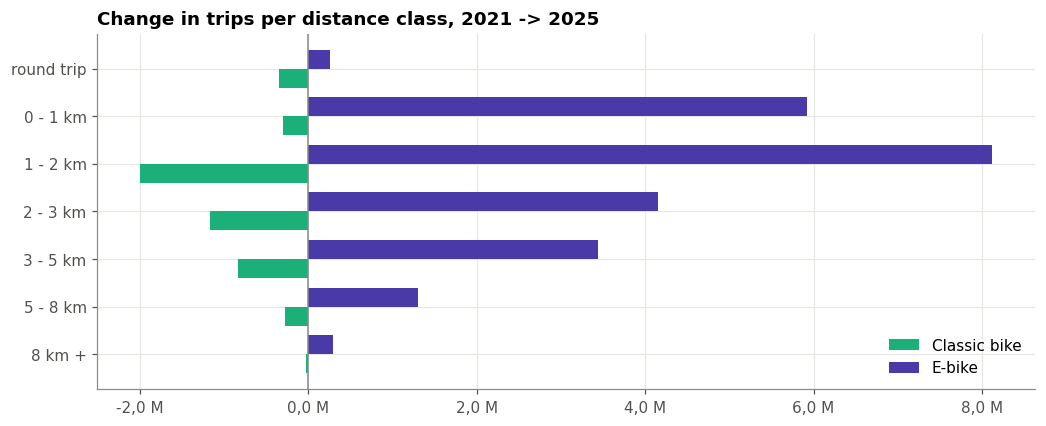

classic trips lost: 4.933.243, e-bike trips gained: 23.496.480
upper bound for replacement: 21,0 % of the e-bike growth
share of the e-bike growth in trips of 3 km or more: 21,4 %


,classic_2021,classic_2025,ebike_2021,ebike_2025,change_classic,change_ebike,ebike_share_2021_%,ebike_share_2025_%
band,,,,,,,,
round trip,686.592,345.395,310.809,564.976,-341.197,254.167,"31,2","62,1"
0 - 1 km,5.920.470,5.625.327,1.798.528,7.726.623,-295.143,5.928.095,"23,3","57,9"
1 - 2 km,6.200.989,4.203.329,2.597.780,10.722.431,-1.997.660,8.124.651,"29,5","71,8"
2 - 3 km,2.850.812,1.684.876,1.635.730,5.791.855,-1.165.936,4.156.125,"36,5","77,5"
3 - 5 km,2.037.624,1.205.220,1.481.850,4.920.846,-832.404,3.438.996,"42,1","80,3"
5 - 8 km,659.747,390.063,636.217,1.941.048,-269.684,1.304.831,"49,1","83,3"
8 km +,91.087,59.868,151.541,441.156,-31.219,289.615,"62,5","88,1"


In [25]:
# A subquery, not a CTE (WITH ...): pg_duckdb 0.3 hands a CTE over this view to the Postgres executor,
# which cannot read the view's r['column'] fields ("Subscripting duckdb.row is not supported").
dist = sql("""
    SELECT year, rideable_type,
           CASE WHEN km < 0.05 THEN -0.5 ELSE floor(least(km, 10) * 2) / 2 END AS km_from,
           count(*) AS trips
    FROM (
        SELECT extract(year FROM started_at)::int AS year, rideable_type,
               sqrt(power((end_lat - start_lat) * 110.54, 2) + power((end_lng - start_lng) * 84.36, 2)) AS km
        FROM citibike.trips
        WHERE started_at >= '2021-01-01'
          AND start_lat BETWEEN 40 AND 41.5 AND start_lng BETWEEN -75 AND -73
          AND end_lat BETWEEN 40 AND 41.5 AND end_lng BETWEEN -75 AND -73
    ) t
    GROUP BY 1, 2, 3
""")
DISTANCE_BANDS = ["round trip", "0 - 1 km", "1 - 2 km", "2 - 3 km", "3 - 5 km", "5 - 8 km", "8 km +"]
dist["band"] = pd.cut(dist.km_from, [-1, 0, 1, 2, 3, 5, 8, np.inf], right=False, labels=DISTANCE_BANDS)

by_band = dist.pivot_table(index="band", columns=["year", "rideable_type"], values="trips",
                           aggfunc="sum", fill_value=0, observed=False)
# FROM_YEAR and TO_YEAR (2021 and 2025) are set in the setup cell; 5.4 compares the same two years.
bands = pd.DataFrame({
    f"classic_{FROM_YEAR}": by_band[FROM_YEAR].classic_bike, f"classic_{TO_YEAR}": by_band[TO_YEAR].classic_bike,
    f"ebike_{FROM_YEAR}": by_band[FROM_YEAR].electric_bike, f"ebike_{TO_YEAR}": by_band[TO_YEAR].electric_bike,
})
bands["change_classic"] = bands[f"classic_{TO_YEAR}"] - bands[f"classic_{FROM_YEAR}"]
bands["change_ebike"] = bands[f"ebike_{TO_YEAR}"] - bands[f"ebike_{FROM_YEAR}"]
for year in (FROM_YEAR, TO_YEAR):
    bands[f"ebike_share_{year}_%"] = (bands[f"ebike_{year}"] / (bands[f"ebike_{year}"] + bands[f"classic_{year}"])
                                      * 100).round(1)

fig, ax = plt.subplots()
y = np.arange(len(bands))
ax.barh(y + 0.2, bands.change_classic, height=0.4, color=COLORS["classic_bike"], label=LABELS["classic_bike"])
ax.barh(y - 0.2, bands.change_ebike, height=0.4, color=COLORS["electric_bike"], label=LABELS["electric_bike"])
ax.set_yticks(y, bands.index.astype(str))
ax.invert_yaxis()
ax.axvline(0, color="#8a8986", linewidth=1)
ax.xaxis.set_major_formatter(millions)
ax.set_title(f"Change in trips per distance class, {FROM_YEAR} -> {TO_YEAR}")
ax.legend(loc="lower right")
plt.show()

lost_classic = -bands.change_classic.clip(upper=0).sum()
gained_ebike = bands.change_ebike.clip(lower=0).sum()
long = ["3 - 5 km", "5 - 8 km", "8 km +"]
print(f"classic trips lost: {fmt(lost_classic)}, e-bike trips gained: {fmt(gained_ebike)}")
print(f"upper bound for replacement: {fmt(lost_classic / gained_ebike * 100, '.1f')} % of the e-bike growth")
print(f"share of the e-bike growth in trips of 3 km or more: "
      f"{fmt(bands.loc[long, 'change_ebike'].sum() / bands.change_ebike.sum() * 100, '.1f')} %")
bands

**How to read it.** Per distance class the green bar is what classic bikes lost, the violet bar what e-bikes
gained. Where both are large in the same class the pattern fits replacement; where only the violet bar is
large it fits addition. The *upper bound* says how much of the e-bike growth replacement can explain at most;
the rest is new trips in any case. The e-bike share per class shows whether e-bikes took over evenly or mainly
on longer trips.

**Reading the result**
- **Replacement explains at most 21,0 % of the e-bike growth.** Classic bikes lost 4.933.243 trips between 2021
  and 2025, e-bikes gained 23.496.480. Even if every lost classic trip became an e-bike trip, four out of five
  e-bike trips are new.
- **The pattern is replacement-shaped, the size is not.** The classic losses and the e-bike gains sit in the same
  classes - 1 - 2 km (-2,0 M classic, +8,1 M e-bike) and 2 - 3 km (-1,2 M, +4,2 M) - so the trips that moved are
  the ordinary short ones, not a new kind of long trip. Only 21,4 % of the e-bike growth is in trips of 3 km or
  more; the 0 - 1 km class alone adds 5,9 M.
- **The longer the trip, the more often an e-bike**, in both years: in 2025 from 57,9 % (0 - 1 km) to 88,1 %
  (8 km +), in 2021 from 23,3 % to 62,5 %. The rise between the two years is largest in the short classes
  (+34,6 pp at 0 - 1 km, +42,3 pp at 1 - 2 km) and smallest at 8 km + (+25,6 pp), where e-bikes already dominated.
- **Round trips fell** from 997 k (2021) to 910 k (2025), the only class whose total went down: leisure loops did
  not follow the growth.
- **What this does not show.** "New" trips are not necessarily *caused* by e-bikes: total ridership grew 68,8 % in
  the same period (3.1), with more members and more stations (5.1). Without a rider id the data cannot say whether
  a person switched. 5.4 checks whether the e-bike shift is at least not an artefact of the new stations.


## 5. Stations

### 5.1 How many stations, and do the identifiers stay stable?
Station analyses only work if a station keeps the same identifier over time. We count the distinct station
ids and names per year, and the number of names that appear under more than one id.

In [26]:
stations = sql("""
    SELECT extract(year FROM started_at)::int AS year,
           count(DISTINCT start_station_id)   AS station_ids,
           count(DISTINCT start_station_name) AS station_names,
           count(*) FILTER (WHERE start_station_id IS NULL) * 100.0 / count(*) AS pct_no_start_station,
           count(*) FILTER (WHERE start_station_id LIKE 'JC%' OR start_station_id LIKE 'HB%') AS jc_hb_trips,
           count(DISTINCT start_station_id) FILTER (WHERE start_station_id LIKE 'JC%' OR start_station_id LIKE 'HB%') AS jc_hb_ids
    FROM citibike.trips WHERE started_at >= '2021-01-01' GROUP BY 1 ORDER BY 1
""")
stations.round(2)

6 rows in 57,3 s


,year,station_ids,station_names,pct_no_start_station,jc_hb_trips,jc_hb_ids
0,2021,1.557,1.569,"0,00",12,1
1,2022,1.752,1.761,"0,00",0,0
2,2023,2.347,2.305,"0,05",360,78
3,2024,2.378,2.273,"0,07",168,63
4,2025,2.343,2.246,"0,04",0,0
5,2026,2.438,2.391,"0,06",0,0


Names with more than one id in the same year point to renumbering; a different id *format* between years
would mean a mapping is needed before stations can be compared across years.

In [27]:
ids = sql("""
    SELECT extract(year FROM started_at)::int AS year, start_station_name, count(DISTINCT start_station_id) AS ids,
           min(start_station_id) AS example_id
    FROM citibike.trips
    WHERE start_station_name IS NOT NULL AND started_at >= '2021-01-01'
    GROUP BY 1, 2
""")
print("Station names with more than one id, per year:")
display(ids[ids.ids > 1].groupby("year").size().rename("names").to_frame().T)
print("Example ids per year (format check):")
ids.groupby("year").example_id.apply(lambda s: list(s.sample(4, random_state=1))).to_frame()

12.545 rows in 55,6 s
Station names with more than one id, per year:


year,2021,2022,2023,2024,2025,2026
names,9,14,105,111,102,50


Example ids per year (format check):


,example_id
year,
2021,"['7640.04', '7450.05', '7918.12', '6579.03']"
2022,"['3202.06', '3803.09', '4060.09', '6460.06']"
2023,"['5270.09', '4550.05', '4816.02', '5569.07']"
2024,"['4993.13', '6140.05', 'JC080', '5300.05']"
2025,"['3172.01', '6422.08', '5676.04', '8531.05']"
2026,"['7944.12', '4138.04', '3887.03', '8122.04']"


**Reading the result**
- The network grows from 1.557 station ids (2021) to 2.438 (2026). From 2023 there are **more ids than names**
  (2.347 against 2.305 in 2023), and the number of names with two ids in one year jumps from 14 (2022) to 105
  (2023). That is the id-format problem of 5.3 (`7386.10` next to `7386.1`), not a wave of renumbering.
- Ids are strings such as `7386.10`: a number with two decimals, so they must stay text in every pipeline. The
  exception: ids like `JC094` or `HB...` are **Jersey City and Hoboken stations that sit in the NYC files**, 540
  trips with 82 such ids between October 2021 and July 2024. Too few to matter for any count, but a station key
  (5.3) must not treat them as New York stations; 04 drops them or assigns them to the `jc` region.


### 5.2 Busiest start stations (2025)

10 rows in 8,0 s


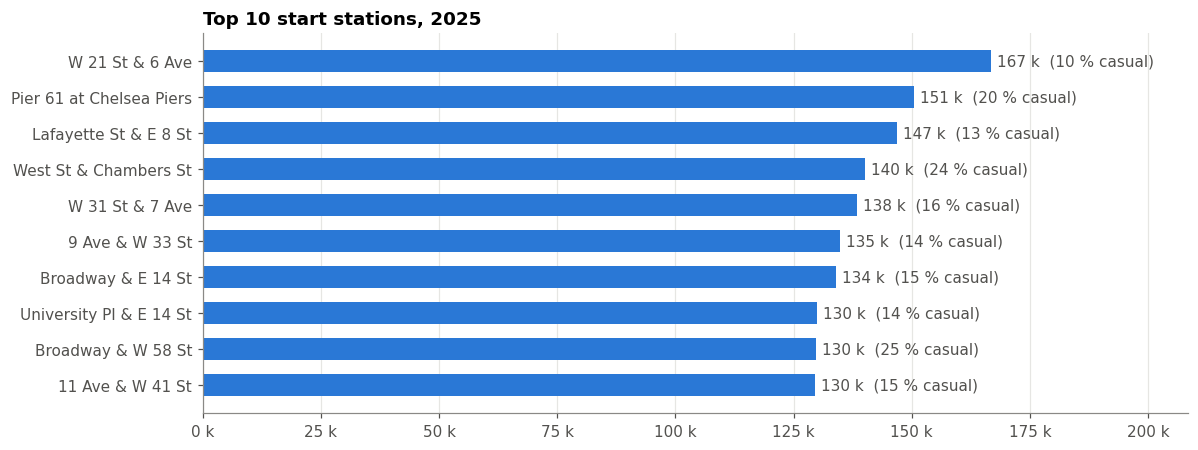

In [28]:
top = sql("""
    SELECT start_station_name, count(*) AS trips,
           count(*) FILTER (WHERE member_casual = 'casual') * 100.0 / count(*) AS casual_pct
    FROM citibike.trips
    WHERE started_at >= '2025-01-01' AND started_at < '2026-01-01' AND start_station_name IS NOT NULL
    GROUP BY 1 ORDER BY trips DESC LIMIT 10
""").round(1)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.barh(top.start_station_name[::-1], top.trips[::-1], color=COLORS["member"], height=0.6)
for y, (n, c) in enumerate(zip(top.trips[::-1], top.casual_pct[::-1])):
    ax.annotate(f"{n / 1e3:.0f} k  ({c:.0f} % casual)", (n, y), xytext=(4, 0), textcoords="offset points",
                va="center", color="#52514e")
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, top.trips.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 start stations, 2025")
plt.tight_layout()
plt.show()

### 5.3 Can we identify a station?
Station ids change (5.1), so "station X is busy" only means something if we know what *station X* is. A station
is a physical place; its id and name are labels that can change. This block measures how stable those labels
are and whether **location** is a better key.

**Approach**
1. One query builds a small table of **station keys**: every (id, name) combination that ever occurs as a start
   station, with first and last trip, number of trips and its coordinates. A few thousand rows, so the rest of
   the analysis runs locally in pandas.
2. **Names with more than one id**: how far apart are those ids? Same spot means renumbered; far apart means
   two different stations that share a name.
3. **Ids with more than one name**: do the names follow each other in time (renamed) or run in parallel
   (inconsistent spelling)?
4. **Physical stations**: cluster the keys on location and count how many places remain.
5. **Does it matter?** Stability over the years, and the 2025 top 10 of 5.2 per name vs per physical station.

**Which coordinates.** For a classic bike the trip starts in a dock, so its coordinates are those of the
station. For an e-bike they are the GPS position of the bike, which varies from trip to trip. We therefore
take the **average of the classic-bike trips** per key, and check with the standard deviation that those
coordinates really are fixed. Keys without any classic-bike trip fall back to the average of all trips.
Coordinates outside the New York area (for example 0, 0) are ignored.

In [29]:
CLASSIC = "rideable_type = 'classic_bike' AND start_lat BETWEEN 40 AND 41.5 AND start_lng BETWEEN -75 AND -73"

keys = sql(f"""
    SELECT start_station_id                                        AS station_id,
           start_station_name                                      AS station_name,
           min(started_at)                                         AS first_seen,
           max(started_at)                                         AS last_seen,
           count(*)                                                AS trips,
           count(*) FILTER (WHERE started_at >= '2025-01-01' AND started_at < '2026-01-01') AS trips_2025,
           count(*) FILTER (WHERE {CLASSIC})                       AS classic_trips,
           avg(start_lat) FILTER (WHERE {CLASSIC})                 AS lat,
           avg(start_lng) FILTER (WHERE {CLASSIC})                 AS lng,
           stddev(start_lat) FILTER (WHERE {CLASSIC})              AS lat_sd,
           stddev(start_lng) FILTER (WHERE {CLASSIC})              AS lng_sd,
           avg(start_lat) FILTER (WHERE start_lat BETWEEN 40 AND 41.5) AS lat_all,
           avg(start_lng) FILTER (WHERE start_lng BETWEEN -75 AND -73) AS lng_all
    FROM citibike.trips
    WHERE started_at >= '2021-01-01' AND start_station_id IS NOT NULL AND start_station_name IS NOT NULL
    GROUP BY 1, 2
""")
keys["first_seen"] = pd.to_datetime(keys.first_seen)
keys["last_seen"] = pd.to_datetime(keys.last_seen)
keys["coords_from"] = np.where(keys.lat.notna(), "classic bikes", "all trips")
keys["lat"] = keys.lat.fillna(keys.lat_all)
keys["lng"] = keys.lng.fillna(keys.lng_all)
keys = keys.dropna(subset=["lat", "lng"])   # no usable coordinates at all; reported below if it happens

# Degrees to metres. Over the size of New York a flat projection around 40.73 N is accurate to well under 1 %.
M_PER_DEG_LAT = 110_540
M_PER_DEG_LNG = 111_320 * np.cos(np.radians(40.73))
keys["x"] = keys.lng * M_PER_DEG_LNG
keys["y"] = keys.lat * M_PER_DEG_LAT
keys["spread_m"] = np.hypot(keys.lat_sd * M_PER_DEG_LAT, keys.lng_sd * M_PER_DEG_LNG)

print(f"{fmt(len(keys))} station keys: {fmt(keys.station_id.nunique())} ids, {fmt(keys.station_name.nunique())} names")
print(f"ids with more than one name: {fmt((keys.groupby('station_id').size() > 1).sum())}")
print(f"names with more than one id: {fmt((keys.groupby('station_name').size() > 1).sum())}")
print(f"coordinates from classic bikes: {fmt((keys.coords_from == 'classic bikes').mean() * 100, '.1f')} % of keys, "
      f"{fmt(keys.trips[keys.coords_from == 'classic bikes'].sum() / keys.trips.sum() * 100, '.1f')} % of trips")
keys.spread_m.describe(percentiles=[.5, .9, .99]).to_frame("spread of classic-bike coordinates (m)").T

2.924 rows in 134,5 s
2.921 station keys: 2.794 ids, 2.746 names
ids with more than one name: 119
names with more than one id: 166
coordinates from classic bikes: 96,9 % of keys, 100,0 % of trips


,count,mean,std,min,50%,90%,99%,max
spread of classic-bike coordinates (m),2.823,"2,72345","58,153",0,0,"0,08321","60,867","3.016,27"


**Reading the coordinate check.** `spread` is the standard deviation of the classic-bike start coordinates
of one key, in metres. If it is close to 0 for almost all keys, every classic trip of a station carries the
same coordinates and the average *is* the station location. A few keys with a large spread point to a station
that moved while keeping its id and name; those are worth a look but do not change the method.

Next we look at the two kinds of label changes. For each group (one name with several ids, or one id with
several names) we compute:
- `spread_m`: the largest distance between two keys in the group;
- `overlap_in_time`: whether the keys were in use at the same time (more than 7 days overlap). Labels that
  follow each other in time are a rename or renumbering; labels used side by side are two stations, or two
  spellings.

In [30]:
BINS = [-1, 50, 300, np.inf]
CLASS_LABELS = ["same spot (< 50 m)", "nearby (50 - 300 m)", "elsewhere (> 300 m)"]

def group_profile(g: pd.DataFrame) -> pd.Series:
    g = g.sort_values("first_seen")
    earlier_end = g.last_seen.cummax().shift()
    return pd.Series({
        "keys": len(g),
        "spread_m": pdist(g[["x", "y"]].to_numpy()).max(),
        "overlap_in_time": bool((g.first_seen < earlier_end - pd.Timedelta(days=7)).any()),
        "trips": g.trips.sum(),
    })

def label_changes(by: str) -> pd.DataFrame:
    multi = keys[keys.groupby(by)[by].transform("size") > 1]
    prof = multi.groupby(by).apply(group_profile, include_groups=False)
    prof["distance"] = pd.cut(prof.spread_m, BINS, labels=CLASS_LABELS)
    return prof

by_name = label_changes("station_name")
by_id = label_changes("station_id")

print("Names with more than one id - how far apart, and used at the same time?")
display(pd.crosstab(by_name.distance, by_name.overlap_in_time, margins=True))
print("Ids with more than one name - how far apart, and used at the same time?")
display(pd.crosstab(by_id.distance, by_id.overlap_in_time, margins=True))

Names with more than one id - how far apart, and used at the same time?


overlap_in_time,False,True,All
distance,,,
same spot (< 50 m),50,109,159
nearby (50 - 300 m),5,2,7
All,55,111,166


Ids with more than one name - how far apart, and used at the same time?


overlap_in_time,False,True,All
distance,,,
same spot (< 50 m),98,18,116
nearby (50 - 300 m),1,0,1
elsewhere (> 300 m),2,0,2
All,101,18,119


**How to read the two tables.** The rows say how far apart the labels are, the columns whether they were
used at the same time.
- *Same spot, not at the same time*: the expected case - a station that got a new id or a new name.
- *Same spot, at the same time*: two labels for one place in parallel, for example two spellings of a name.
- *Elsewhere*: two different stations sharing a label. Grouping by that label (as 5.2 does by name) adds up
  trips from two places.

Examples per class make this concrete, followed by a check on spelling: names that become identical after
lower-casing, `&` → `and`, removing punctuation, shortening common words (`Avenue` → `Ave`, `Street` → `St`)
and dropping ordinal suffixes (`60th` → `60`). The list of abbreviations is a first guess; extend it when the
examples show other variants.

In [31]:
def show_examples(prof: pd.DataFrame, by: str, n: int = 2) -> pd.DataFrame:
    picked = prof.groupby(["distance", "overlap_in_time"], observed=True).head(n).index
    return (keys[keys[by].isin(picked)]
            .sort_values([by, "first_seen"])
            [["station_name", "station_id", "first_seen", "last_seen", "trips", "lat", "lng"]]
            .assign(first_seen=lambda d: d.first_seen.dt.strftime("%Y-%m"),
                    last_seen=lambda d: d.last_seen.dt.strftime("%Y-%m")))

print("Examples: names with more than one id")
display(show_examples(by_name, "station_name"))
print("Examples: ids with more than one name")
display(show_examples(by_id, "station_id"))

ABBREVIATIONS = {r"\bavenue\b": "ave", r"\bstreet\b": "st", r"\bplace\b": "pl", r"\bboulevard\b": "blvd",
                 r"\bparkway\b": "pkwy", r"\b(\d+)(st|nd|rd|th)\b": r"\1"}   # 60th -> 60

def normalise(names: pd.Series) -> pd.Series:
    out = (names.str.lower().str.replace("&", " and ", regex=False)
           .str.replace(r"[^a-z0-9 ]", " ", regex=True))
    for pattern, short in ABBREVIATIONS.items():
        out = out.str.replace(pattern, short, regex=True)
    return out.str.split().str.join(" ")

names = pd.DataFrame({"station_name": keys.station_name.unique()})
names["normalised"] = normalise(names.station_name)
variants = names[names.groupby("normalised").station_name.transform("size") > 1].sort_values("normalised")
print(f"{fmt(variants.normalised.nunique())} names have more than one spelling "
      f"({fmt(len(variants))} spellings); first examples:")
variants.head(10)

Examples: names with more than one id


,station_name,station_id,first_seen,last_seen,trips,lat,lng
508,11 St & 43 Ave,6438.04,2021-01,2025-01,18.558,"40,7519","-73,948"
1329,11 St & 43 Ave,6438.05,2025-01,2026-08,12.839,"40,7518","-73,948"
1185,2 Ave & 37 St,3460.04,2023-10,2023-11,145,"40,6563","-74,010"
1281,2 Ave & 37 St,3460.06,2024-01,2025-08,4.737,"40,6562","-74,009"
471,2 Ave & E 99 St,7386.10,2021-01,2026-08,76.429,"40,7863","-73,946"
936,2 Ave & E 99 St,7386.1,2023-01,2025-05,7.127,"40,7863","-73,946"
1962,24 Ave & 26 St,7152.10,2021-01,2026-08,43.974,"40,7746","-73,919"
928,24 Ave & 26 St,7152.1,2023-01,2025-05,5.810,"40,7746","-73,919"
1678,31 St & Broadway,6789.04,2021-01,2023-11,66.818,"40,7616","-73,926"
2731,31 St & Broadway,6789.20,2024-02,2025-07,52.762,"40,7621","-73,925"


Examples: ids with more than one name


,station_name,station_id,first_seen,last_seen,trips,lat,lng
652,5 Ave & 67 St,2782.02,2021-03,2026-08,7.505,"40,6358","-74,020"
2164,5 Ave & 66 St,2782.02,2021-03,2023-10,8.054,"40,6357","-74,020"
2073,58 St & 2 Ave - Brooklyn Army Terminal Vaccination Site,3138.09,2021-01,2022-05,3.088,"40,6445","-74,022"
810,58 St & 2 Ave,3138.09,2022-05,2025-01,6.378,"40,6445","-74,022"
582,57 St & 1 Ave - Brooklyn Army Terminal Vaccination Site,3178.02,2021-01,2022-05,3.002,"40,6464","-74,023"
2289,57 St & 1 Ave,3178.02,2022-05,2026-08,10.104,"40,6464","-74,023"
128,Court St & Nelson St,4077.07,2021-01,2025-11,79.302,"40,6764","-73,999"
2811,Court St & Huntington St,4077.07,2025-11,2026-08,18.788,"40,6760","-73,999"
689,Boerum Pl\t& Pacific St,4488.09,2021-05,2022-09,33.173,"40,6885","-73,991"
734,Boerum Pl & Pacific St,4488.09,2021-06,2022-08,218,"40,6885","-73,991"


49 names have more than one spelling (99 spellings); first examples:


,station_name,normalised
2500,16 St & 4 Ave,16 st and 4 ave
615,16th St & 4th Ave,16 st and 4 ave
2613,34 Ave & Vernon Blvd,34 ave and vernon blvd
512,34th Ave & Vernon Blvd,34 ave and vernon blvd
750,51 St & Hobart St,51 st and hobart st
1835,51 St & Hobart St,51 st and hobart st
90,Avenue D & E 10 St,ave d and e 10 st
2493,Ave D & E 10 St,ave d and e 10 st
1153,Ave D & E 12 St,ave d and e 12 st
2184,Avenue D & E 12 St,ave d and e 12 st


**Physical stations.** We now ignore the labels and group keys that lie close together into one *place*.
`linkage(..., method="complete")` builds the groups so that **every** pair of keys within a place is closer
than the threshold - so a row of neighbouring stations cannot chain into one big place, which a looser method
("single" linkage) would allow.

The threshold is a choice. Two docking stations are rarely less than ~100 m apart, while a renumbered station
stays on the same spot, so 50 m should merge relabelled stations and keep neighbours apart. To see how much
the result depends on that choice we count the places for 25, 50 and 100 m: if the counts barely move, the
choice does not matter much.

In [32]:
tree = linkage(keys[["x", "y"]].to_numpy(), method="complete")
sensitivity = pd.DataFrame({"threshold_m": [25, 50, 100]})
sensitivity["places"] = [fcluster(tree, t, criterion="distance").max() for t in sensitivity.threshold_m]
display(sensitivity)

keys["place"] = fcluster(tree, 50, criterion="distance")
places = keys.groupby("place").agg(
    ids=("station_id", "nunique"), names=("station_name", "nunique"),
    first_seen=("first_seen", "min"), last_seen=("last_seen", "max"),
    trips=("trips", "sum"), trips_2025=("trips_2025", "sum"),
)
print(f"{fmt(len(keys))} station keys -> {fmt(len(places))} physical places (50 m)")
print(f"places with more than one id: {fmt((places.ids > 1).sum())}, "
      f"with more than one name: {fmt((places.names > 1).sum())}")

,threshold_m,places
0,25,2.632
1,50,2.581
2,100,2.476


2.921 station keys -> 2.581 physical places (50 m)
places with more than one id: 196, with more than one name: 151


**Does it matter?** Two checks. First the stability over the years: per year in which a place first appears,
how many places are still in use at the end of the data (a trip in the last two months). Then the 2025 top 10
of 5.2, once per **name** (as 5.2 does) and once per **physical place**, labelled with the name that had the
most trips in 2025. If both lists match, 5.2 holds; if not, rankings per station need the place key.

In [33]:
data_end = keys.last_seen.max()
stability = (places.assign(first_year=places.first_seen.dt.year,
                           still_in_use=places.last_seen >= data_end - pd.Timedelta(days=60))
             .groupby("first_year").agg(places=("ids", "size"), still_in_use=("still_in_use", "sum")))
stability["still_in_use_%"] = (stability.still_in_use / stability.places * 100).round(1)
display(stability)

label = (keys.sort_values("trips_2025", ascending=False).drop_duplicates("place")
         .set_index("place").station_name.rename("label"))
top_by_name = (keys.groupby("station_name").trips_2025.sum().nlargest(10)
               .reset_index().rename(columns={"station_name": "by_name", "trips_2025": "trips_by_name"}))
top_by_place = (places.trips_2025.nlargest(10).to_frame().join(label).reset_index(drop=True)
                .rename(columns={"label": "by_place", "trips_2025": "trips_by_place"}))
comparison = pd.concat([top_by_name, top_by_place[["by_place", "trips_by_place"]]], axis=1)
comparison.index = comparison.index + 1
comparison

,places,still_in_use,still_in_use_%
first_year,,,
2021,1.538,1.428,"92,8"
2022,218,206,"94,5"
2023,528,432,"81,8"
2024,62,49,"79,0"
2025,76,75,"98,7"
2026,159,158,"99,4"


,by_name,trips_by_name,by_place,trips_by_place
1,W 21 St & 6 Ave,166.769,Pier 61 at Chelsea Piers,185.287
2,Pier 61 at Chelsea Piers,150.527,W 21 St & 6 Ave,166.769
3,Lafayette St & E 8 St,146.959,Park Ave & E 42 St,156.212
4,West St & Chambers St,140.184,Lafayette St & E 8 St,146.959
5,W 31 St & 7 Ave,138.332,West St & Chambers St,140.184
6,9 Ave & W 33 St,134.851,W 31 St & 7 Ave,138.332
7,Broadway & E 14 St,133.954,9 Ave & W 33 St,134.851
8,University Pl & E 14 St,130.041,Broadway & E 14 St,133.954
9,Broadway & W 58 St,129.717,University Pl & E 14 St,130.041
10,11 Ave & W 41 St,129.501,Broadway & W 58 St,129.717


**Check: what did the clustering merge in the top 10?** Per physical place Pier 61 and Park Ave & E 42 St
come out higher than per name, so their trips are spread over several keys. Before we trust the ranking per
place we look at which keys each top-10 place contains, how far each key lies from the busiest key of that
place (`m_from_main`), and when each key was in use.
- Same or almost the same name, a different id (or `7386.1` vs `7386.10`), a few metres apart: the same
  station - merging is right.
- A clearly different name, both in use in 2025 with many trips: possibly two real stations next to each
  other. Then the place is a *busy spot* rather than a *busy station*.

In [34]:
top_places = places.trips_2025.nlargest(10).index
place_rank = pd.Series(range(1, len(top_places) + 1), index=top_places, name="place_rank")

merged = keys[keys.place.isin(top_places) & (keys.groupby("place").place.transform("size") > 1)].copy()
main = merged.sort_values("trips_2025").groupby("place")[["x", "y"]].transform("last")
merged["m_from_main"] = np.hypot(merged.x - main.x, merged.y - main.y).round(1)
(merged.assign(place_rank=merged.place.map(place_rank))
       .sort_values(["place_rank", "trips_2025"], ascending=[True, False])
       .assign(first_seen=lambda d: d.first_seen.dt.strftime("%Y-%m"), last_seen=lambda d: d.last_seen.dt.strftime("%Y-%m"))
       [["place_rank", "station_name", "station_id", "first_seen", "last_seen", "trips", "trips_2025", "m_from_main"]]
       .set_index("place_rank"))

,station_name,station_id,first_seen,last_seen,trips,trips_2025,m_from_main
place_rank,,,,,,,
1,Pier 61 at Chelsea Piers,6233.04,2024-04,2026-08,358.411,150.527,"0,0"
1,W 20 St & 11 Ave,6306.07,2024-09,2026-07,64.776,34.760,"40,8"
3,Park Ave & E 42 St,6432.09,2024-12,2026-08,187.535,107.707,"0,0"
3,Park Ave & E 41 St,6432.08,2024-12,2026-08,82.701,48.505,"36,6"
3,Pershing Square South,6432.08,2021-01,2021-10,28.838,0,"36,5"
3,Pershing Square North,6432.09,2021-01,2021-10,72.586,0,"0,0"
10,Broadway & W 58 St,6948.10,2021-01,2026-08,564.216,127.134,"0,0"
10,Broadway & W 58 St,6948.1,2022-12,2025-05,77.108,2.583,"0,0"


**Reading the result**

**The coordinates are reliable.** 2.921 station keys (2.794 ids, 2.746 names). Classic-bike coordinates exist
for 96,9 % of the keys, covering practically all trips. The spread within a key is 0 m at the median and
below 0,1 m for 90 % of the keys: every classic trip of a station carries the same coordinates. About 1 % of
the keys spread more than 60 m - stations that moved while keeping id and name.

**Station ids are not clean.**
- **The same id in two formats:** `7386.10` and `7386.1`, `6948.10` and `6948.1`, `6789.20` and `6789.2`. A
  trailing zero was lost because the id was treated as a number somewhere. Our ingest reads ids as text
  (`citibike_data.py`), so this is most likely already in Citi Bike's files. The short form occurs over the
  **whole period**, January 2021 to August 2026 (119 raw ids, 3,65 M trips; counted in `04_PH_data_preparation.ipynb`
  §3.2): for most ids in parallel with the two-decimal form, for nine ids (`6131.1`, `3593.1`, ...) as the only
  form. The examples above, which end in May 2025, are not representative of the range. It explains at least part
  of the 109 names that have two ids *at the same time* on the same spot; we have not counted how much. 04 also
  found a second format noise, not visible in this sample: ids with a suffix (`5308.04_`, `5348.06_old`,
  `6912.01_Pillar`), an extra or temporary dock of the same station.
- **Renumbering:** 50 names moved to a new id on the same spot, one after the other (for example
  `11 St & 43 Ave`: `6438.04` → `6438.05` in January 2025).

**Station names are mostly consistent, with four kinds of noise.**
- **Real renames** (98 ids, same spot, one name after the other): `Pershing Square North` →
  `Park Ave & E 42 St`, `Court St & Nelson St` → `Court St & Huntington St`.
- **Two names in parallel** for one id (18), for example `5 Ave & 67 St` and `5 Ave & 66 St`.
- **Spelling variants:** 49 names occur in 99 spellings (`16 St` / `16th St`, `Ave D` / `Avenue D`, double
  spaces). One name even contains a tab character.
- **System stations** that are not public stations: `Lab - NYC` / `Prototype Lab` and `SYS032`
  (`Morgan WH station`, `Park Ave Depot`). Few trips, but they do not belong in station analyses.

**Location alone cannot tell a renumbered station from a neighbour.** Clustering on 50 m turns the keys into
2.581 places (2.632 at 25 m, 2.476 at 100 m). The check on the top 10 shows what that merges:
- rightly: `Broadway & W 58 St` under `6948.10` and `6948.1` (the format error);
- wrongly, if you want stations: `Park Ave & E 42 St` (`6432.09`) and `Park Ave & E 41 St` (`6432.08`) are two
  stations 37 m apart, both in use at the same time - in 2021 they were `Pershing Square North` and
  `South`, then gone for three years. The same holds for `Pier 61 at Chelsea Piers` and
  `W 20 St & 11 Ave`, 41 m apart.

Two stations side by side are 37 - 41 m apart, while a renumbered station can shift further (`6789.04` →
`6789.20`, about 80 m). No distance threshold separates both cases. **Time** does: keys in use *at the same
time* with different ids are different stations; keys that *follow each other* on about the same spot, or
whose ids are equal after fixing the format, are one station.

**Places come and go.** Of the 1.538 places in use in 2021, 92,8 % still see trips in the last two months of the
data. 2023 was the big expansion year (528 new places, 81,8 % still in use), 2024 added few (62). A station-level
model needs a rule for places that open or close inside the training period.

**Definition used in this project.** A **station** is a normalised id, with consecutive ids on the same spot
linked into one station - this matches how Citi Bike counts and which dock fills up or runs empty. A group of
stations within ~50 m is a **hotspot**, an optional level above it. The 2025 number 1 is therefore
`W 21 St & 6 Ave` (166.769 trips) as a station; as a hotspot `Pier 61` + `W 20 St & 11 Ave` (185.287) comes
first. The top 10 per name in 5.2 is close to the per-station ranking here, but only because the label
problems happen to miss those stations; it is not a reliable method.

### 5.4 Network growth and the e-bike share
The network grew from ~1.550 to ~2.400 stations (5.1), partly into outer areas where trips are longer - the
trips for which people pick an e-bike. Part of the rising e-bike share could therefore come from **new areas**
rather than from **people switching**. That matters for the hypothesis that e-bikes replace classic trips.

We split the trips into two groups:
- **panel**: places (5.3, 50 m) that were already in use in January 2021 *and* are still in use at the end of
  the data - the same locations over the whole period;
- **rest**: every other place - opened later, or closed along the way.

Here the **place** is the right unit, not the station: the question is about *where* people ride, and a
renumbered station must not show up as a new location.

If the e-bike share rises just as fast within the panel, it is a real shift in behaviour. If it rises much
less there, network growth is a large part of the story. A **shift-share decomposition** splits the change
in the total e-bike share between 2021 and 2025 into a *within* part (the share changes inside each group)
and a *mix* part (the weight of the rest group changes).

261.985 rows in 69,8 s
panel: 1.146 of 2.581 places


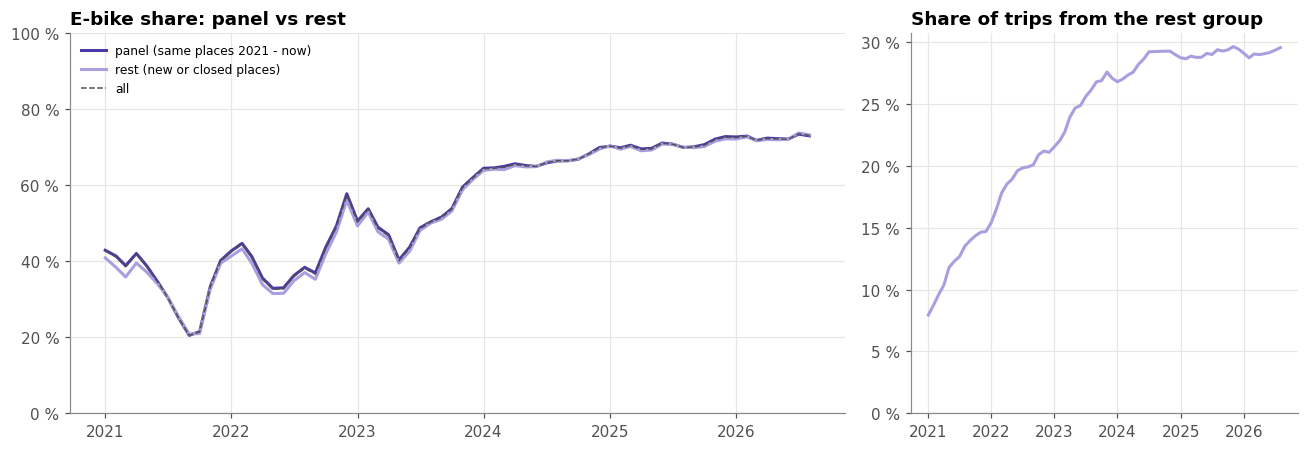

trips           ebike_share_%       weight_%      
group     panel      rest         panel  rest    panel  rest
year                                                        
2021   23680889   3423486          32.0  30.5     87.4  12.6
2022   23978279   5819904          39.6  38.2     80.5  19.5
2023   26185629   8876392          50.3  49.8     74.7  25.3
2024   31595554  12666382          66.1  66.0     71.4  28.6
2025   32426946  13314338          70.5  70.3     70.9  29.1
2026   21340659   8795012          72.6  72.5     70.8  29.2

Shift-share 2021 -> 2025:


,value
total_change_pp,"38,63"
within_pp,"38,78"
mix_pp,"-0,15"
mix_part_%,"-0,39"


In [35]:
station_month = sql("""
    SELECT date_trunc('month', started_at) AS month, start_station_id AS station_id,
           start_station_name AS station_name, rideable_type, count(*) AS trips
    FROM citibike.trips
    WHERE started_at >= '2021-01-01' AND start_station_id IS NOT NULL AND start_station_name IS NOT NULL
    GROUP BY 1, 2, 3, 4
""")
station_month["month"] = pd.to_datetime(station_month.month)
station_month = station_month.merge(keys[["station_id", "station_name", "place"]],
                                    on=["station_id", "station_name"], how="inner")

panel_places = places.index[(places.first_seen < "2021-02-01")
                            & (places.last_seen >= data_end - pd.Timedelta(days=60))]
station_month["group"] = np.where(station_month.place.isin(panel_places), "panel", "rest")
print(f"panel: {fmt(len(panel_places))} of {fmt(len(places))} places")

per_month = station_month.pivot_table(index="month", columns=["group", "rideable_type"], values="trips",
                                      aggfunc="sum", fill_value=0)
share = pd.DataFrame({g: per_month[g].electric_bike / per_month[g].sum(axis=1) * 100 for g in ["panel", "rest"]})
share["all"] = per_month.xs("electric_bike", axis=1, level=1).sum(axis=1) / per_month.sum(axis=1) * 100
rest_weight = per_month["rest"].sum(axis=1) / per_month.sum(axis=1) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2, 1]})
ax1.plot(share.index, share.panel, color=COLORS["electric_bike"], label="panel (same places 2021 - now)")
ax1.plot(share.index, share.rest, color="#a99fe0", label="rest (new or closed places)")
ax1.plot(share.index, share["all"], color="#52514e", linewidth=1, linestyle="--", label="all")
ax1.set_ylim(0, 100)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax1.set_title("E-bike share: panel vs rest")
ax1.legend(loc="upper left", fontsize=8)
ax2.plot(rest_weight.index, rest_weight, color="#a99fe0")
ax2.set_ylim(0, None)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax2.set_title("Share of trips from the rest group")
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

yearly_groups = (station_month.assign(year=station_month.month.dt.year,
                                      ebike=np.where(station_month.rideable_type == "electric_bike",
                                                     station_month.trips, 0))
                 .groupby(["year", "group"])[["trips", "ebike"]].sum())
yearly_groups["ebike_share_%"] = (yearly_groups.ebike / yearly_groups.trips * 100).round(1)
yearly_groups["weight_%"] = (yearly_groups.trips / yearly_groups.groupby("year").trips.transform("sum") * 100).round(1)

def shift_share(y0: int, y1: int) -> pd.Series:
    """Midpoint decomposition: total change = within + mix, exactly.

    A group without trips in one of the two years has no share there; it then takes the share of the other
    year, so its whole contribution counts as mix (it only changed weight)."""
    g0 = yearly_groups.loc[y0].reindex(["panel", "rest"]).fillna(0)
    g1 = yearly_groups.loc[y1].reindex(["panel", "rest"]).fillna(0)
    s0, s1 = g0.ebike / g0.trips, g1.ebike / g1.trips
    s0, s1 = s0.fillna(s1), s1.fillna(s0)
    w0, w1 = g0.trips / g0.trips.sum(), g1.trips / g1.trips.sum()
    within = ((w0 + w1) / 2 * (s1 - s0)).sum() * 100
    mix = ((s0 + s1) / 2 * (w1 - w0)).sum() * 100
    return pd.Series({"total_change_pp": within + mix, "within_pp": within, "mix_pp": mix,
                      "mix_part_%": mix / (within + mix) * 100})

display(yearly_groups[["trips", "ebike_share_%", "weight_%"]].unstack("group"))
print(f"Shift-share {FROM_YEAR} -> {TO_YEAR}:")
shift_share(FROM_YEAR, TO_YEAR).round(2).to_frame("value")

**How to read it.** `within_pp` is the rise of the e-bike share that happens *inside* the groups -
people at the same places choosing e-bikes more often. `mix_pp` is the rise that comes only from the rest group
getting a bigger weight; it is large only if new places both carry many trips *and* have a clearly higher
e-bike share. `mix_part_%` is the part of the total change that network growth explains.

**Reading the result.** The e-bike share rose 38,63 pp between 2021 and 2025. **Within +38,78 pp, mix -0,15 pp**:
the whole rise happened *inside* the groups, at the same kind of place. The mix part is even slightly negative:
the rest group gained weight (12,6 % -> 29,1 % of the trips) while its share was marginally *lower* than the
panel's. The chart says the same - the panel and rest lines lie on top of each other over the whole period.
Network growth therefore does not explain the e-bike shift; it is a change in how people ride, at every place.
(`03_hypothesis.ipynb` §2 derived the same split, +38,77 / -0,14 pp, from the rounded shares in the table above,
at a time when this cell had no output.)


## 6. Findings

Numbers from the run of this notebook on 6 October 2026 (data January 2021 - August 2026): all cells, top to
bottom, in one fresh kernel. The sample-based numbers (section 4) are reproducible because the sample is fixed
(`ride_id` ending in `00`). Format: dot = thousands, comma = decimals.

**Data and quality**
- **Complete period:** 68 monthly files, January 2021 - August 2026, no missing months; 212.310.903 raw trips,
  7,88 GB of Parquet. 185 trips start on 31 December 2020 and are left out of every analysis by month or day.
- **Cleaning removes 0,057 %** (121.336 trips): 119.082 trips over 24 h and 1.760 with a negative duration.
  Only 494 trips are under one minute - Citi Bike already removes those before publishing. The view holds
  exactly raw minus removed (212.189.567 trips).
- **Missing values** are small and concentrated where expected: end station 0,24 %, end coordinates 0,21 %
  (e-bikes parked outside a dock), start station 0,04 %. The end columns do not fail together: at least 61.974
  trips have end coordinates but no end station. `ride_id`, bike type and user type are never empty, and
  `ride_id` is unique in the month we checked (4.986.246 trips, 0 duplicates).
- **Days:** 2.067 days with trips and 2 days without any (2 February 2021, 23 February 2026), both in a
  snowstorm (3.5). The ten lowest days are all weather or holidays, so no day points to a data problem.
- **The fixed sample of 2025** (178.652 trips, 0,390 % of the year against 1/256 = 0,391 % expected)
  matches the full year on member share (82,55 % vs 82,55 %), e-bike share (70,38 % vs 70,47 %) and the spread
  over the months: 13 of 14 checks fall within the 95 % margin, March is 0,15 pp over-represented, which is what
  chance produces (4.1).
- **Stations** (5.1, 5.3): 1.557 station ids in 2021 growing to 2.438 in 2026. Neither id nor name is a stable
  key: ids appear in two formats (`7386.10` / `7386.1`, over the whole period, most likely already in the source
  files) and sometimes with a suffix (`5308.04_`, `6912.01_Pillar`), stations get renumbered (50 names) and renamed (98 ids), 49 names have spelling
  variants, a few system stations (`Lab - NYC`, `SYS032`) are mixed in, and 540 trips carry Jersey City or
  Hoboken ids (`JC...`, `HB...`). Coordinates are reliable (spread under 0,1 m for 90 % of the keys), but
  location alone merges real neighbours 37 - 41 m apart; telling a renumbered station from a neighbour needs
  id + time + location. **Definition:** a *station* is a normalised id with consecutive ids on the same spot
  linked; stations within ~50 m form a *hotspot*.

**Behaviour**
- **Seasonality and growth:** a strong summer peak every year. The member peak rises from 2,2 M trips per month
  (2021) to 4,3 M (2025); the casual peak stays at 0,9 - 1,2 M. Casual users are a **shrinking minority**:
  26,7 % of the trips in 2021, 17,4 % in 2025.
- **Two user groups, two purposes:** members ride at **commuter peaks** (08h and 17h - 18h on weekdays); casual
  users ride in **weekend afternoons**. Casual users also make more round trips (3,9 - 6,5 % vs 1,2 - 1,9 % for
  members).
- **Casual users ride longer:** median 12,7 min vs 8,2 min. Mann-Whitney U, one-sided p < 0,001, rank-biserial
  r = 0,31 - a **medium** effect, so the difference is both real and relevant.
- **E-bikes take over:** the e-bike share rose from 34 % (first 12 months) to 72 % (last 12 months); Spearman
  rho = 0,95 over 68 months, a strong monotonic trend. Classic-bike trips *fell* in absolute numbers (18,5 M in
  2021 to 13,5 M in 2025) while e-bike trips almost quadrupled (8,6 M to 32,2 M). Two caveats: the share swings
  widely in 2021 - 2023 for reasons that look like supply rather than season, and it flattens at 70 - 73 % from
  2025 on - whether it is *still* rising is tested in `03_hypothesis.ipynb`.
- **E-bikes add more than they replace** (4.6): even if every lost classic trip became an e-bike trip, that
  explains at most 21,0 % of the e-bike growth. The growth sits in short trips (1 - 2 km +8,1 M, 0 - 1 km
  +5,9 M; only 21,4 % in trips of 3 km or more), and e-bikes are chosen more often the longer the trip (2025:
  57,9 % at 0 - 1 km to 88,1 % at 8 km +). Total ridership grew 68,8 % in the same years, so "new" does not mean
  "caused by e-bikes".
- **The e-bike shift is not an effect of the new stations** (5.4): places in use since January 2021 went from
  32,0 % to 70,5 % e-bike, all other places from 30,5 % to 70,3 %. Shift-share 2021 -> 2025: within +38,78 pp,
  mix -0,15 pp - the whole rise happened at the same kind of place.
- **Bike choice hardly depends on user type:** casual users pick an e-bike slightly more often (75,3 % vs
  69,5 % in 2025). The chi-square test is "significant" (p < 0,001), but **Cramér's V = 0,049 is negligible**:
  with 46 M trips any difference reaches significance. This is exactly why we report effect sizes.
- **No implausible speeds** in the sample (none above 40 km/h; median 9,6 km/h casual, 11,4 km/h member,
  straight-line). E-bikes are about 3 km/h faster than classic bikes for both groups.

**Weather and holidays** (3.5 and 3.6; weather from `citibike.weather_daily`, holidays from `citibike.calendar_day`)
- **Rain lowers demand step by step:** median relative demand 1,03 on dry days down to 0,66 above 25 mm
  (Spearman rho = -0,448 over 2.067 days). Rain also raises the e-bike share, in every year, but the gap between
  wet and dry days shrank from +7,9 pp (2022) to +1 - 2 pp (2024 - 2026). Temperature and wind hardly change the
  bike choice.
- **The lowest days are weather or holidays:** of the ten lowest days six are snow days, two heavy rain, one
  Thanksgiving with rain and one Christmas Day.
- **A weekday day off has about 17 % fewer trips** (relative demand 0,829) and a lower member share (79,7 % vs
  83,5 %); the members' morning peak shrinks by a third. The effect differs per holiday: Christmas Day 0,32,
  Thanksgiving 0,43 and Christmas Eve 0,47 at one end, Memorial Day 0,91 and Veterans Day 1,00 at the other;
  Lincoln's Birthday and Election Day are no day off for most riders. Easter is barely visible (0,92 - 0,95).

**To carry forward**
- `03_hypothesis`: the strongest "going green" signal is the **shift from classic bikes to e-bikes**. 4.6 already
  shows that e-bikes mostly *add* trips rather than replace them, so the open questions are whether the share is
  **still rising** now that it flattens (tested there as H-A, paired by calendar month) and how much the weather
  moves demand (H-D, without the holidays). The e-bike share measures use, not preference: fleet size is not in
  the data.
- `04_data_preparation`: keep the cleaning rules of the view; filter on `started_at`, not on the file a trip is
  stored in; treat "no end station" and "no end coordinates" as different cases; leave the two snowstorm days
  without trips out or mark them, do not set them to 0 silently. Weather: impute the 23 missing wind values and
  4 missing snow depths; the precipitation classes are right-closed (a day with exactly 2,0 mm is "0 - 2 mm").
  Holidays: use the actual date *and* the observed day off, grouped by the size of the effect (3.6). Stations:
  normalise ids to two decimals (`7386.1` -> `7386.10`), drop the system stations (`Lab - NYC`, `SYS...`) and the
  `JC`/`HB` ids, clean names (tabs, double spaces, one spelling per station) and build a station key from
  id + time + location as defined in 5.3, with the hotspot as an optional level. Per-station analyses use that
  key, not the name.


Close the database connections.

In [36]:
engine.dispose()